# Phase 3 — OCR evaluation and diagnosis

**Historical execution record.** Open-phase and pending-decision statements below
describe this notebook's original handoff. For current status and source reuse,
see the [Phase 3 delivery record](../docs/phases/phase-3.md). Code, outputs,
and copied-definition provenance are retained unchanged.

Workshops **5–8**, completed autonomously at the learner's request. Phase 3 remains
**open**. Workshop 9 and final pipeline freeze/closure require a joint decision.

This notebook answers four questions:

1. What do our correctness metrics actually measure?
2. How well does the unchanged pretrained recognizer read validation documents?
3. What does a seven-field request cost on this machine?
4. Which failures justify a specific next experiment?

Read the explanation before each code cell, predict the result, then compare with
the saved output. The worked examples and reflection prompts remain usable even
though this execution was delegated.

Contract: [experiment design](../EXPERIMENT_DESIGN.md),
[approved workshop sequence](../docs/workshops/phase-3.md),
[roadmap](../PROJECT.md). Longer explanations:
[evaluation](../docs/learning/ocr-evaluation.md),
[generation and timing](../docs/learning/ocr-generation-and-timing.md).

Run from a fresh kernel using the project `.venv`. This notebook is self-contained:
selected definitions from `04b` are copied explicitly, with cell provenance and
source hashes; no `%run`, hidden kernel state, or training-sample inference is
needed. Copying is temporary notebook-stage reuse. Source extraction remains a
closure decision. Rerunning creates a new local artifact directory.

In [1]:
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from transformers import (
    GenerationConfig,
    TrOCRProcessor,
    VisionEncoderDecoderModel,
)


current_directory = Path.cwd().resolve()

if (current_directory / "PROJECT.md").is_file():
    repository_root = current_directory
elif (current_directory.parent / "PROJECT.md").is_file():
    repository_root = current_directory.parent
else:
    raise FileNotFoundError(
        "Start Jupyter from the repository root or notebooks directory."
    )

dataset_root = repository_root / "data" / "raw"

print("Repository root:", repository_root)
print("Dataset root:", dataset_root)

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository root: /home/raspiestchip/kyc-router
Dataset root: /home/raspiestchip/kyc-router/data/raw


In [2]:
import copy
import hashlib
import importlib.metadata
import os
import platform
import subprocess
import time
from collections import Counter
from datetime import datetime, timezone
from IPython.display import Markdown, display
from collections.abc import Mapping

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
artifact_directory = repository_root / "outputs" / "phase3" / run_id
artifact_directory.mkdir(parents=True, exist_ok=False)
print("Run:", run_id)
print("Artifacts:", artifact_directory)

Run: 20261012T220250890693Z
Artifacts: /home/raspiestchip/kyc-router/outputs/phase3/20261012T220250890693Z


In [3]:
phase_2_config_path = (
    repository_root
    / "configs"
    / "controlled_degradations_v1.json"
)

with phase_2_config_path.open(encoding="utf-8") as config_file:
    phase_2_config = json.load(config_file)

canonical_width = phase_2_config["canonical_width"]
canonical_height = phase_2_config["canonical_height"]

In [4]:
split_manifest_path = (
    repository_root
    / "splits"
    / "alb_id_v1.csv"
)

split_manifest = pd.read_csv(
    split_manifest_path,
    dtype={"sample_id": "string"},
)
split_counts = split_manifest["split"].value_counts()

assert len(split_manifest) == 100
assert split_manifest["identity_key"].is_unique
assert split_counts.to_dict() == {
    "train": 70,
    "validation": 15,
    "test": 15,
}

split_counts

split
train         70
validation    15
test          15
Name: count, dtype: int64

In [5]:
document_type = "alb_id"

raw_to_canonical_field = {
    "number": "document_number",
    "surname": "surname",
    "name": "given_names",
    "birth_date": "date_of_birth",
    "expiry_date": "expiry_date",
    "nationality": "nationality",
    "gender": "sex",
}

ocr_model_id = "microsoft/trocr-small-printed"
ocr_model_revision = (
    "04e994ab854b0089d4929f48c2b4dbe2ce78a340"
)

print("Required fields:", list(raw_to_canonical_field.values()))
print("OCR checkpoint:", ocr_model_id)
print("Revision:", ocr_model_revision)

Required fields: ['document_number', 'surname', 'given_names', 'date_of_birth', 'expiry_date', 'nationality', 'sex']
OCR checkpoint: microsoft/trocr-small-printed
Revision: 04e994ab854b0089d4929f48c2b4dbe2ce78a340


## Shared normalization and validation contract

These are the exact implemented `04b` rules, reused for predictions and truth.
Case, harmless whitespace, and supported date formats are representation choices.
Changing a digit or guessing a nationality would change the answer, so we do not
do either. Malformed dates retain their text, allowing CER to diagnose the error.
Validity is a separate signal: a nine-digit number can be well-formed and wrong.

In [6]:
import unicodedata


def is_missing_scalar(value):
    if value is None:
        return True

    missing_result = pd.isna(value)

    return isinstance(
        missing_result,
        (bool, np.bool_),
    ) and bool(missing_result)


def normalize_common_text(value):
    if is_missing_scalar(value):
        return None

    text = unicodedata.normalize(
        "NFC",
        str(value),
    )

    text = " ".join(text.split())

    return text.casefold()

In [7]:
common_only_fields = frozenset(
    {
        "surname",
        "given_names",
        "nationality",
    }
)


def normalize_document_number(value):
    normalized_value = normalize_common_text(value)

    if normalized_value is None:
        return None

    without_whitespace = "".join(
        normalized_value.split()
    )

    return without_whitespace.upper()


def normalize_sex(value):
    normalized_value = normalize_common_text(value)

    if normalized_value is None:
        return None

    return normalized_value.upper()


def normalize_non_date_field(field_name, value):
    if field_name in common_only_fields:
        return normalize_common_text(value)

    if field_name == "document_number":
        return normalize_document_number(value)

    if field_name == "sex":
        return normalize_sex(value)

    raise ValueError(
        f"{field_name!r} is not a supported non-date field."
    )

In [8]:
import re
from datetime import datetime


supported_date_patterns = (
    (
        re.compile(r"^\d{2}-\d{2}-\d{4}$"),
        "%d-%m-%Y",
    ),
    (
        re.compile(r"^\d{2}/\d{2}/\d{4}$"),
        "%d/%m/%Y",
    ),
    (
        re.compile(r"^\d{2}\.\d{2}\.\d{4}$"),
        "%d.%m.%Y",
    ),
    (
        re.compile(r"^\d{4}-\d{2}-\d{2}$"),
        "%Y-%m-%d",
    ),
)


def parse_supported_date_text(normalized_text):
    for pattern, date_format in supported_date_patterns:
        if not pattern.fullmatch(normalized_text):
            continue

        try:
            return datetime.strptime(
                normalized_text,
                date_format,
            ).date()
        except ValueError:
            return None

    return None


def normalize_date(value):
    normalized_text = normalize_common_text(value)

    if normalized_text is None:
        return None

    parsed_date = parse_supported_date_text(
        normalized_text
    )

    if parsed_date is None:
        return normalized_text

    return parsed_date.isoformat()

In [9]:
date_fields = frozenset(
    {
        "date_of_birth",
        "expiry_date",
    }
)

required_field_names = tuple(
    raw_to_canonical_field.values()
)

assert len(required_field_names) == 7
assert len(set(required_field_names)) == 7


def normalize_field_value(field_name, value):
    if field_name not in required_field_names:
        raise ValueError(
            f"Unknown canonical field: {field_name!r}"
        )

    if field_name in date_fields:
        return normalize_date(value)

    return normalize_non_date_field(
        field_name,
        value,
    )


def normalize_document_values(
    field_values,
    required_fields,
):
    expected_fields = set(required_fields)
    received_fields = set(field_values)

    missing_fields = expected_fields - received_fields
    unexpected_fields = received_fields - expected_fields

    if missing_fields or unexpected_fields:
        raise ValueError(
            "Invalid document schema. "
            f"Missing: {sorted(missing_fields)}; "
            f"unexpected: {sorted(unexpected_fields)}."
        )

    return {
        field_name: normalize_field_value(
            field_name,
            field_values[field_name],
        )
        for field_name in required_fields
    }

In [10]:
canonical_date_pattern = re.compile(
    r"^\d{4}-\d{2}-\d{2}$"
)

alb_id_validation_config = {
    "document_number_pattern": re.compile(
        r"^\d{9}$"
    ),
    "allowed_nationalities": frozenset(
        {
            "shqiptare/albanian",
        }
    ),
    "allowed_sex_values": frozenset(
        {
            "M",
            "F",
        }
    ),
}


def parse_canonical_date(value):
    if not isinstance(value, str):
        return None

    if not canonical_date_pattern.fullmatch(value):
        return None

    try:
        return datetime.strptime(
            value,
            "%Y-%m-%d",
        ).date()
    except ValueError:
        return None

In [11]:
def validate_field_value(
    field_name,
    normalized_value,
    *,
    validation_config,
):
    if field_name not in required_field_names:
        raise ValueError(
            f"Unknown canonical field: {field_name!r}"
        )

    errors = []

    if is_missing_scalar(normalized_value):
        errors.append("missing_value")

        return {
            "is_valid": False,
            "errors": tuple(errors),
        }

    if not isinstance(normalized_value, str):
        errors.append("not_a_string")

        return {
            "is_valid": False,
            "errors": tuple(errors),
        }

    if normalized_value == "":
        errors.append("empty_value")

    elif field_name in date_fields:
        if parse_canonical_date(
            normalized_value
        ) is None:
            errors.append("invalid_date")

    elif field_name == "document_number":
        pattern = validation_config[
            "document_number_pattern"
        ]

        if not pattern.fullmatch(normalized_value):
            errors.append(
                "invalid_document_number_shape"
            )

    elif field_name == "nationality":
        allowed_values = validation_config[
            "allowed_nationalities"
        ]

        if normalized_value not in allowed_values:
            errors.append("unknown_nationality")

    elif field_name == "sex":
        allowed_values = validation_config[
            "allowed_sex_values"
        ]

        if normalized_value not in allowed_values:
            errors.append("invalid_sex_value")

    return {
        "is_valid": len(errors) == 0,
        "errors": tuple(errors),
    }

In [12]:
def validate_document_values(
    normalized_values,
    *,
    required_fields,
    validation_config,
):
    expected_fields = set(required_fields)
    received_fields = set(normalized_values)

    missing_fields = tuple(
        sorted(expected_fields - received_fields)
    )
    unexpected_fields = tuple(
        sorted(received_fields - expected_fields)
    )

    field_validations = {
        field_name: validate_field_value(
            field_name=field_name,
            normalized_value=normalized_values.get(
                field_name
            ),
            validation_config=validation_config,
        )
        for field_name in required_fields
    }

    document_errors = []

    date_of_birth = parse_canonical_date(
        normalized_values.get("date_of_birth")
    )
    expiry_date = parse_canonical_date(
        normalized_values.get("expiry_date")
    )

    if (
        date_of_birth is not None
        and expiry_date is not None
        and expiry_date <= date_of_birth
    ):
        document_errors.append(
            "expiry_not_after_date_of_birth"
        )

    schema_is_valid = (
        not missing_fields
        and not unexpected_fields
    )

    fields_are_valid = all(
        result["is_valid"]
        for result in field_validations.values()
    )

    return {
        "is_valid": (
            schema_is_valid
            and fields_are_valid
            and not document_errors
        ),
        "schema_is_valid": schema_is_valid,
        "missing_fields": missing_fields,
        "unexpected_fields": unexpected_fields,
        "field_validations": field_validations,
        "document_errors": tuple(document_errors),
    }

In [13]:
normalization_contract_version = "v1"
validation_contract_version = "alb_id_v1"
assert normalize_common_text("  AHMETI  ") == "ahmeti"
assert normalize_common_text("Jose\u0301") == normalize_common_text("José")
assert normalize_common_text("José") != normalize_common_text("Jose")
assert normalize_date("15/10/1973") == "1973-10-15"
assert normalize_date("31-02-2000") == "31-02-2000"
assert normalize_document_number("391 378355") == "391378355"

## Workshop 5 — Understand the measurements

### 5.1 A worked example before the implementation

For this small exercise only, a document has three required fields. The real
benchmark always uses all seven. Normalization makes `AHMETI` agree with `Ahmeti`
and converts the supported date formats. An empty document number stays wrong.

By hand: raw equality is **2/6**; normalized equality is **4/6**. Field EM is
document number **1/2**, surname **1/2**, birth date **2/2**. Their unweighted mean
is **2/3**. Only the first document is entirely right: Document EM is **1/2**.
There are nine deletions for the missing number and one substitution in `Ajetl`:
**10 edits / 49 reference characters = 20.41% CER**.

EM treats one incorrect character as a failed field. CER describes the extent of
the text difference. Neither tells us whether a value merely looks plausible.

In [14]:
toy_required_fields = ("document_number", "surname", "date_of_birth")
toy_records = [
    ("toy/01", {"document_number": "391378355", "surname": "Ahmeti", "date_of_birth": "1973-10-15"},
     {"document_number": "391378355", "surname": "AHMETI", "date_of_birth": "15-10-1973"}),
    ("toy/02", {"document_number": "123456789", "surname": "Ajeti", "date_of_birth": "1990-01-02"},
     {"document_number": "", "surname": "Ajetl", "date_of_birth": "1990-01-02"}),
]
pd.DataFrame([
    {"identity_key": identity, "field": field, "truth": truth[field], "prediction": prediction[field]}
    for identity, truth, prediction in toy_records for field in toy_required_fields
])

,identity_key,field,truth,prediction
0,toy/01,document_number,391378355,391378355
1,toy/01,surname,Ahmeti,AHMETI
2,toy/01,date_of_birth,1973-10-15,15-10-1973
3,toy/02,document_number,123456789,
4,toy/02,surname,Ajeti,Ajetl
5,toy/02,date_of_birth,1990-01-02,1990-01-02


### 5.2 Levenshtein distance: count the smallest edit sequence

The dynamic-programming table considers prefixes of the two strings. A cell asks
for the cheapest way to transform the reference prefix into the prediction
prefix: delete a reference character, insert a predicted character, or substitute
one character. Matching characters cost zero. The last cell is the distance.

We also trace one optimal alignment to retain substitution/deletion/insertion
counts. Ties use a fixed priority (diagonal, deletion, insertion); another optimal
alignment can distribute edit types differently while keeping the same CER.
Characters here are normalized Unicode code points, not tokenizer tokens or bytes.

In [15]:
def levenshtein_edits(reference, prediction):
    n, m = len(reference), len(prediction)
    distances = np.zeros((n + 1, m + 1), dtype=np.int64)
    distances[:, 0] = np.arange(n + 1)
    distances[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            distances[i, j] = min(
                distances[i - 1, j] + 1,
                distances[i, j - 1] + 1,
                distances[i - 1, j - 1] + (reference[i - 1] != prediction[j - 1]),
            )
    i, j = n, m
    counts = {"substitutions": 0, "deletions": 0, "insertions": 0}
    while i or j:
        if i and j and distances[i, j] == distances[i - 1, j - 1] + (reference[i - 1] != prediction[j - 1]):
            counts["substitutions"] += int(reference[i - 1] != prediction[j - 1])
            i, j = i - 1, j - 1
        elif i and distances[i, j] == distances[i - 1, j] + 1:
            counts["deletions"] += 1
            i -= 1
        else:
            counts["insertions"] += 1
            j -= 1
    return {"edit_distance": int(distances[n, m]), **counts}

def scoring_text(value):
    return "" if is_missing_scalar(value) else str(value)

def score_document(truth, prediction, *, required_fields):
    # An unparseable structured output loses all required fields, but remains auditable.
    structural_failure = False
    if isinstance(prediction, str):
        try:
            prediction = json.loads(prediction)
        except (ValueError, TypeError):
            prediction = None
    if not isinstance(prediction, Mapping):
        structural_failure = True
        prediction = {}
    expected = set(required_fields)
    if set(truth) != expected:
        raise ValueError("Ground-truth schema must equal the required fields.")
    missing = sorted(expected - set(prediction))
    extra = sorted(set(prediction) - expected)
    rows = []
    for field in required_fields:
        raw_truth = truth[field]
        raw_prediction = prediction.get(field)
        reference = scoring_text(normalize_field_value(field, raw_truth))
        hypothesis = scoring_text(normalize_field_value(field, raw_prediction))
        truth_validation = validate_field_value(field, reference, validation_config=alb_id_validation_config)
        if not reference or not truth_validation["is_valid"]:
            raise ValueError(f"Invalid reference for {field}: {raw_truth!r}")
        validation = validate_field_value(field, hypothesis, validation_config=alb_id_validation_config)
        date_is_valid = field not in date_fields or validation["is_valid"]
        rows.append({
            "field": field,
            "raw_ground_truth": raw_truth,
            "raw_prediction": raw_prediction,
            "normalized_ground_truth": reference,
            "normalized_prediction": hypothesis,
            "raw_exact_match": not is_missing_scalar(raw_prediction) and raw_prediction == raw_truth,
            "normalized_exact_match": bool(hypothesis) and date_is_valid and hypothesis == reference,
            "reference_characters": len(reference),
            "missing_key": field in missing,
            "prediction_is_valid": validation["is_valid"],
            "validation_errors": list(validation["errors"]),
            **levenshtein_edits(reference, hypothesis),
        })
    return rows, {
        "structural_failure": structural_failure,
        "schema_is_valid": not structural_failure and not missing and not extra,
        "missing_fields": missing,
        "extra_fields": extra,
        "document_exact_match": all(row["normalized_exact_match"] for row in rows),
    }

def summarize_scores(field_scores, document_scores, *, required_fields):
    # Reject duplicates or dropped observations rather than inflating accuracy.
    keys = ["identity_key", "source"]
    assert not field_scores.duplicated(keys + ["field"]).any()
    assert not document_scores.duplicated(keys).any()
    assert set(field_scores["field"]) == set(required_fields)
    expected_index = pd.MultiIndex.from_tuples(
        [(row.identity_key, row.source, field) for row in document_scores.itertuples()
         for field in required_fields], names=keys + ["field"])
    actual_index = pd.MultiIndex.from_frame(field_scores[keys + ["field"]])
    assert set(actual_index) == set(expected_index)
    fields = field_scores.groupby(["source", "field"], as_index=False).agg(
        samples=("field", "size"), raw_matches=("raw_exact_match", "sum"),
        normalized_matches=("normalized_exact_match", "sum"),
        edit_distance=("edit_distance", "sum"), reference_characters=("reference_characters", "sum"),
        invalid_predictions=("prediction_is_valid", lambda x: (~x).sum()),
    )
    fields["raw_field_em"] = fields["raw_matches"] / fields["samples"]
    fields["field_em"] = fields["normalized_matches"] / fields["samples"]
    fields["cer"] = fields["edit_distance"] / fields["reference_characters"]
    summaries = []
    for source, group in fields.groupby("source", sort=True):
        docs = document_scores.loc[document_scores["source"] == source]
        summaries.append({
            "source": source, "documents": len(docs), "field_samples": int(group["samples"].sum()),
            "raw_matches": int(group["raw_matches"].sum()),
            "normalized_matches": int(group["normalized_matches"].sum()),
            "raw_field_em": group["raw_field_em"].mean(),
            "macro_field_em": group["field_em"].mean(),
            "micro_field_em": group["normalized_matches"].sum() / group["samples"].sum(),
            "edit_distance": int(group["edit_distance"].sum()),
            "reference_characters": int(group["reference_characters"].sum()),
            "cer": group["edit_distance"].sum() / group["reference_characters"].sum(),
            "document_matches": int(docs["document_exact_match"].sum()),
            "document_em": docs["document_exact_match"].mean(),
            "schema_failures": int((~docs["schema_is_valid"]).sum()),
        })
    return fields, pd.DataFrame(summaries)

In [16]:
toy_rows, toy_documents = [], []
for identity, truth, prediction in toy_records:
    rows, document = score_document(truth, prediction, required_fields=toy_required_fields)
    toy_rows.extend({"identity_key": identity, "source": "toy", **row} for row in rows)
    toy_documents.append({"identity_key": identity, "source": "toy", **document})
toy_evaluation = pd.DataFrame(toy_rows)
toy_field_summary, toy_summary = summarize_scores(
    toy_evaluation, pd.DataFrame(toy_documents), required_fields=toy_required_fields)
assert toy_summary.iloc[0]["raw_matches"] == 2
assert toy_summary.iloc[0]["normalized_matches"] == 4
assert np.isclose(toy_summary.iloc[0]["macro_field_em"], 2 / 3)
assert toy_summary.iloc[0]["document_matches"] == 1
assert toy_summary.iloc[0]["edit_distance"] == 10
assert toy_summary.iloc[0]["reference_characters"] == 49
display(toy_evaluation)
display(toy_field_summary)
display(toy_summary)

,identity_key,source,field,raw_ground_truth,raw_prediction,normalized_ground_truth,normalized_prediction,raw_exact_match,normalized_exact_match,reference_characters,missing_key,prediction_is_valid,validation_errors,edit_distance,substitutions,deletions,insertions
0,toy/01,toy,document_number,391378355,391378355,391378355,391378355,True,True,9,False,True,[],0,0,0,0
1,toy/01,toy,surname,Ahmeti,AHMETI,ahmeti,ahmeti,False,True,6,False,True,[],0,0,0,0
2,toy/01,toy,date_of_birth,1973-10-15,15-10-1973,1973-10-15,1973-10-15,False,True,10,False,True,[],0,0,0,0
3,toy/02,toy,document_number,123456789,,123456789,,False,False,9,False,False,[empty_value],9,0,9,0
4,toy/02,toy,surname,Ajeti,Ajetl,ajeti,ajetl,False,False,5,False,True,[],1,1,0,0
5,toy/02,toy,date_of_birth,1990-01-02,1990-01-02,1990-01-02,1990-01-02,True,True,10,False,True,[],0,0,0,0


,source,field,samples,raw_matches,normalized_matches,edit_distance,reference_characters,invalid_predictions,raw_field_em,field_em,cer
0,toy,date_of_birth,2,1,2,0,20,0,0.5,1.0,0.000000
1,toy,document_number,2,1,1,9,18,1,0.5,0.5,0.500000
2,toy,surname,2,0,1,1,11,0,0.0,0.5,0.090909


,source,documents,field_samples,raw_matches,normalized_matches,raw_field_em,macro_field_em,micro_field_em,edit_distance,reference_characters,cer,document_matches,document_em,schema_failures
0,toy,2,6,2,4,0.333333,0.666667,0.666667,10,49,0.204082,1,0.5,0


### 5.3 Edge cases and denominator checks

Missing required keys and explicit empty values stay in the denominator. Invalid
JSON is a structural failure with empty predictions for every required field.
Extra keys do not earn or remove seven-field credit, but are schema violations.
An invalid date cannot earn date EM. CER still counts its text edits.

Corpus CER is **sum(edits) / sum(reference lengths)**, rather than the mean of
individual CERs. A long name and a one-character sex field otherwise get equal
CER weight. CER can exceed 100% when there are many insertions.

For this balanced dataset macro and micro Field EM coincide. We still implement
macro explicitly so the definition survives changes in field applicability.
With 15 identities per source, one field success changes that field's accuracy
by 6.67 percentage points. Template/photo observations of the same identity are
paired; they do not create 30 independent identities.

In [17]:
assert levenshtein_edits("kitten", "sitting")["edit_distance"] == 3
assert levenshtein_edits("abc", "")["deletions"] == 3
assert levenshtein_edits("", "abc")["insertions"] == 3
assert levenshtein_edits("abc", "abc")["edit_distance"] == 0
assert levenshtein_edits("a", "aaaa")["edit_distance"] / len("a") == 3

edge_truth = {
    "document_number": "123456789", "surname": "José", "given_names": "Agim",
    "date_of_birth": "15-10-1973", "expiry_date": "07-08-2025",
    "nationality": "Shqiptare/Albanian", "sex": "M",
}
edge_cases = {
    "perfect": edge_truth.copy(),
    "missing_key": {k: v for k, v in edge_truth.items() if k != "surname"},
    "empty": {**edge_truth, "surname": ""},
    "null": {**edge_truth, "surname": None},
    "invalid_date": {**edge_truth, "date_of_birth": "31-02-2000"},
    "extra_key": {**edge_truth, "unused": "anything"},
    "invalid_json": '{"surname":',
    "json_array": '[]',
    "equivalent_unicode": {**edge_truth, "surname": "JOSE\u0301"},
    "lost_diacritic": {**edge_truth, "surname": "Jose"},
    "wrong_but_valid_number": {**edge_truth, "document_number": "123456788"},
}
edge_checks = []
for name, prediction in edge_cases.items():
    rows, result = score_document(edge_truth, prediction, required_fields=required_field_names)
    edge_checks.append({"case": name, "correct_fields": sum(r["normalized_exact_match"] for r in rows), **result})
edge_checks = pd.DataFrame(edge_checks).set_index("case")
assert edge_checks.loc["perfect", "correct_fields"] == 7
assert edge_checks.loc["equivalent_unicode", "correct_fields"] == 7
assert edge_checks.loc["extra_key", "document_exact_match"]
assert not edge_checks.loc["extra_key", "schema_is_valid"]
for name in ["missing_key", "empty", "null", "invalid_date", "lost_diacritic", "wrong_but_valid_number"]:
    assert edge_checks.loc[name, "correct_fields"] == 6
for name in ["invalid_json", "json_array"]:
    assert edge_checks.loc[name, "correct_fields"] == 0
    assert edge_checks.loc[name, "structural_failure"]

# Unequal sample counts: macro gives fields equal weight; micro gives rows equal weight.
unequal_field_rates = pd.DataFrame({"matches": [9, 0], "samples": [10, 1]})
assert np.isclose((unequal_field_rates.matches / unequal_field_rates.samples).mean(), 0.45)
assert np.isclose(unequal_field_rates.matches.sum() / unequal_field_rates.samples.sum(), 9 / 11)
# A ratio of sums is deliberately different from averaging per-example CERs.
assert not np.isclose((1 / 1 + 1 / 9) / 2, (1 + 1) / (1 + 9))
display(edge_checks)
print("Metric checks passed.")

,correct_fields,structural_failure,schema_is_valid,missing_fields,extra_fields,document_exact_match
case,,,,,,
perfect,7,False,True,[],[],True
missing_key,6,False,False,[surname],[],False
empty,6,False,True,[],[],False
null,6,False,True,[],[],False
invalid_date,6,False,True,[],[],False
extra_key,7,False,False,[],[unused],True
invalid_json,0,True,False,"[date_of_birth, document_number, expiry_date, ...",[],False
json_array,0,True,False,"[date_of_birth, document_number, expiry_date, ...",[],False
equivalent_unicode,7,False,True,[],[],True


Metric checks passed.


**Workshop 5 reflection.** Why can a result have low CER but zero Document EM?
Why must a missing prediction remain a scored row? If raw EM improves but
normalized EM does not, what changed? These questions can be answered from the
toy table without running the recognizer.

## Workshop 6 — Measure the untouched validation baseline

### 6.1 Reuse the pipeline and enforce the split boundary

The following geometry/crop/recognition functions are unchanged copies from
`04b`. The loader rejects test identities before image access. The validation
identity list is determined only by the frozen manifest. Full annotation JSON
files are parsed as dataset containers, but only allowed validation records are
selected; test images, labels, and predictions are never evaluated or displayed.

Known field boxes and ground-truth document corners isolate recognition from
localization. That simplification is part of the experiment, not a deployed
document detector. Cropping uses geometry; transcription strings are passed
only to the scorer, never as decoder prompts or generation constraints.

In [18]:
def load_via_records_by_filename(annotation_path):
    with annotation_path.open(
        encoding="utf-8"
    ) as annotation_file:
        via_document = json.load(annotation_file)

    metadata = via_document["_via_img_metadata"]
    records = list(metadata.values())

    records_by_filename = {
        record["filename"]: record
        for record in records
    }

    if len(records_by_filename) != len(records):
        raise ValueError(
            f"Duplicate filenames in {annotation_path}"
        )

    return records_by_filename

In [19]:
template_annotation_path = (
    dataset_root
    / "templates"
    / "annotations"
    / f"{document_type}.json"
)

photo_annotation_path = (
    dataset_root
    / "photo"
    / "annotations"
    / f"{document_type}.json"
)

template_records_by_filename = (
    load_via_records_by_filename(
        template_annotation_path
    )
)

photo_records_by_filename = (
    load_via_records_by_filename(
        photo_annotation_path
    )
)

assert len(template_records_by_filename) == 100
assert len(photo_records_by_filename) == 100

print(
    "Template annotation records:",
    len(template_records_by_filename),
)

print(
    "Photo annotation records:",
    len(photo_records_by_filename),
)

Template annotation records: 100
Photo annotation records: 100


In [20]:
manifest_by_identity = split_manifest.set_index(
    "identity_key",
    verify_integrity=True,
)

manifest_by_identity.head()

/tmp/ipykernel_351241/327312918.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  manifest_by_identity = split_manifest.set_index(


,document_type,sample_id,split,split_seed
identity_key,,,,
alb_id/38,alb_id,38,train,2026
alb_id/06,alb_id,06,train,2026
alb_id/77,alb_id,77,train,2026
alb_id/69,alb_id,69,train,2026
alb_id/02,alb_id,02,train,2026


In [21]:
def load_alb_id_assets(
    identity_key,
    *,
    manifest_index,
    dataset_root,
    template_record_index,
    photo_record_index,
):
    if identity_key not in manifest_index.index:
        raise KeyError(
            f"Unknown identity: {identity_key}"
        )

    manifest_row = manifest_index.loc[identity_key]

    split_name = manifest_row["split"]

    if split_name == "test":
        raise PermissionError(
            "Test identities are sealed during "
            "Phase 3 development."
        )

    identity_document_type = (
        manifest_row["document_type"]
    )

    if identity_document_type != "alb_id":
        raise ValueError(
            "Phase 3 supports only alb_id."
        )

    sample_id = str(manifest_row["sample_id"])
    filename = f"{sample_id}.jpg"

    template_image_path = (
        dataset_root
        / "templates"
        / "images"
        / identity_document_type
        / filename
    )

    photo_image_path = (
        dataset_root
        / "photo"
        / "images"
        / identity_document_type
        / filename
    )

    template_bgr = cv2.imread(
        str(template_image_path)
    )

    photo_bgr = cv2.imread(
        str(photo_image_path)
    )

    if template_bgr is None:
        raise FileNotFoundError(
            template_image_path
        )

    if photo_bgr is None:
        raise FileNotFoundError(
            photo_image_path
        )

    try:
        template_record = (
            template_record_index[filename]
        )

        photo_record = (
            photo_record_index[filename]
        )
    except KeyError as error:
        raise KeyError(
            f"Missing annotation for {filename}"
        ) from error

    return {
        "identity_key": identity_key,
        "split": split_name,
        "document_type": identity_document_type,
        "sample_id": sample_id,
        "filename": filename,
        "template_bgr": template_bgr,
        "photo_bgr": photo_bgr,
        "template_record": template_record,
        "photo_record": photo_record,
    }

In [22]:
def find_field_region(record, field_name):
    matching_regions = [
        region
        for region in record["regions"]
        if region["region_attributes"].get("field_name") == field_name
    ]

    if len(matching_regions) != 1:
        raise ValueError(
            f"Expected exactly one region named {field_name!r}, "
            f"found {len(matching_regions)}."
        )

    return matching_regions[0]


def extract_document_corners(photo_record):
    doc_quad_region = find_field_region(photo_record, "doc_quad")
    shape = doc_quad_region["shape_attributes"]

    document_corners = np.asarray(
        list(
            zip(
                shape["all_points_x"],
                shape["all_points_y"],
            )
        ),
        dtype=np.float32,
    )

    if document_corners.shape != (4, 2):
        raise ValueError(
            f"Expected four document corners, got {document_corners.shape}."
        )

    return document_corners


def rectify_document(
    photo_bgr,
    document_corners,
    output_width,
    output_height,
):
    destination_corners = np.asarray(
        [
            [0, 0],
            [output_width - 1, 0],
            [output_width - 1, output_height - 1],
            [0, output_height - 1],
        ],
        dtype=np.float32,
    )

    homography = cv2.getPerspectiveTransform(
        document_corners,
        destination_corners,
    )

    return cv2.warpPerspective(
        photo_bgr,
        homography,
        (output_width, output_height),
    )

# These functions represent the stable phase 2 geometry.

In [23]:
def make_canonical_observation(
    assets,
    source,
    output_width,
    output_height,
):
    if source == "template":
        canonical_bgr = cv2.resize(
            assets["template_bgr"],
            (output_width, output_height),
            interpolation=cv2.INTER_AREA,
        )

    elif source == "photo":
        document_corners = extract_document_corners(
            assets["photo_record"]
        )

        canonical_bgr = rectify_document(
            photo_bgr=assets["photo_bgr"],
            document_corners=document_corners,
            output_width=output_width,
            output_height=output_height,
        )

    else:
        raise ValueError(
            f"Unknown source {source!r}. Expected 'template' or 'photo'."
        )

    canonical_rgb = cv2.cvtColor(
        canonical_bgr,
        cv2.COLOR_BGR2RGB,
    )

    expected_shape = (output_height, output_width, 3)

    if canonical_rgb.shape != expected_shape:
        raise ValueError(
            f"Expected canonical shape {expected_shape}, "
            f"got {canonical_rgb.shape}."
        )

    if canonical_rgb.dtype != np.uint8:
        raise TypeError(
            f"Expected uint8 pixels, got {canonical_rgb.dtype}."
        )

    return {
        "identity_key": assets["identity_key"],
        "split": assets["split"],
        "source": source,
        "canonical_rgb": canonical_rgb,
        "template_record": assets["template_record"],
        "template_source_width": assets["template_bgr"].shape[1],
        "template_source_height": assets["template_bgr"].shape[0],
    }

In [24]:
field_crop_config = {
    "padding_x": 0.10,
    "minimum_padding_x": 12,
    "padding_top": 0.10,
    "padding_bottom": 0.40,
}


def scale_field_shape(
    shape,
    source_width,
    source_height,
    target_width,
    target_height,
):
    return {
        "x": round(shape["x"] * target_width / source_width),
        "y": round(shape["y"] * target_height / source_height),
        "width": round(
            shape["width"] * target_width / source_width
        ),
        "height": round(
            shape["height"] * target_height / source_height
        ),
    }


def crop_field(
    image_rgb,
    shape,
    *,
    padding_x,
    minimum_padding_x,
    padding_top,
    padding_bottom,
):
    x = shape["x"]
    y = shape["y"]
    width = shape["width"]
    height = shape["height"]

    if width <= 0 or height <= 0:
        raise ValueError(f"Invalid field shape: {shape}")

    image_height, image_width = image_rgb.shape[:2]

    horizontal_padding = max(
        round(width * padding_x),
        minimum_padding_x,
    )
    top_padding = round(height * padding_top)
    bottom_padding = round(height * padding_bottom)

    bounds = {
        "x1": max(0, x - horizontal_padding),
        "y1": max(0, y - top_padding),
        "x2": min(
            image_width,
            x + width + horizontal_padding,
        ),
        "y2": min(
            image_height,
            y + height + bottom_padding,
        ),
    }

    crop_rgb = image_rgb[
        bounds["y1"]:bounds["y2"],
        bounds["x1"]:bounds["x2"],
    ].copy()

    if crop_rgb.size == 0:
        raise ValueError(
            f"Empty crop produced from shape {shape}."
        )

    return crop_rgb, bounds

In [25]:
def extract_field_crops(
    observation,
    field_mapping,
    crop_config,
):
    canonical_rgb = observation["canonical_rgb"]
    target_height, target_width = canonical_rgb.shape[:2]

    field_crops = {}

    for raw_field_name, canonical_field_name in field_mapping.items():
        field_region = find_field_region(
            observation["template_record"],
            raw_field_name,
        )

        field_attributes = field_region["region_attributes"]

        if "value" not in field_attributes:
            raise ValueError(
                f"Field {raw_field_name!r} has no ground-truth value."
            )

        canonical_shape = scale_field_shape(
            shape=field_region["shape_attributes"],
            source_width=observation["template_source_width"],
            source_height=observation["template_source_height"],
            target_width=target_width,
            target_height=target_height,
        )

        crop_rgb, crop_bounds = crop_field(
            image_rgb=canonical_rgb,
            shape=canonical_shape,
            **crop_config,
        )

        field_crops[canonical_field_name] = {
            "raw_field_name": raw_field_name,
            "canonical_field_name": canonical_field_name,
            "ground_truth": field_attributes["value"],
            "canonical_shape": canonical_shape,
            "crop_bounds": crop_bounds,
            "crop_rgb": crop_rgb,
        }

    return field_crops

In [26]:
def recognize_field_crop(
    crop_rgb,
    *,
    processor,
    model,
    device,
    generation_config,
):
    if crop_rgb.ndim != 3 or crop_rgb.shape[2] != 3:
        raise ValueError(
            f"Expected an RGB image, got shape {crop_rgb.shape}."
        )

    if crop_rgb.dtype != np.uint8:
        raise TypeError(
            f"Expected uint8 pixels, got {crop_rgb.dtype}."
        )

    if model.training:
        raise RuntimeError(
            "The OCR model is in training mode. Call model.eval() first."
        )

    pixel_values = processor(
        images=crop_rgb,
        return_tensors="pt",
    ).pixel_values.to(device)

    with torch.inference_mode():
        generated_ids = model.generate(
            pixel_values=pixel_values,
            generation_config=generation_config,
        )

    raw_prediction = processor.decode(
        generated_ids[0].detach().cpu(),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return {
        "raw_prediction": raw_prediction,
        "generated_token_ids": (
            generated_ids[0].detach().cpu().tolist()
        ),
        "model_input_shape": tuple(pixel_values.shape),
        "model_input_dtype": str(pixel_values.dtype),
        "inference_device": str(pixel_values.device),
    }

In [27]:
def recognize_all_field_crops(
    field_crops,
    *,
    processor,
    model,
    device,
    generation_config,
):
    field_results = {}

    for field_name, field_data in field_crops.items():
        recognition = recognize_field_crop(
            crop_rgb=field_data["crop_rgb"],
            processor=processor,
            model=model,
            device=device,
            generation_config=generation_config,
        )

        field_results[field_name] = {
            "raw_field_name": field_data["raw_field_name"],
            "canonical_field_name": field_name,
            "ground_truth": field_data["ground_truth"],
            "canonical_shape": field_data["canonical_shape"],
            "crop_bounds": field_data["crop_bounds"],
            "crop_shape": field_data["crop_rgb"].shape,
            **recognition,
        }

    return field_results

In [28]:
def ocr_canonical_observation(
    observation,
    *,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
):
    field_crops = extract_field_crops(
        observation=observation,
        field_mapping=field_mapping,
        crop_config=crop_config,
    )

    field_results = recognize_all_field_crops(
        field_crops=field_crops,
        processor=processor,
        model=model,
        device=device,
        generation_config=generation_config,
    )

    expected_fields = set(field_mapping.values())

    if set(field_results) != expected_fields:
        raise RuntimeError(
            "The OCR result does not contain exactly the "
            "required canonical fields."
        )

    return {
        "identity_key": observation["identity_key"],
        "split": observation["split"],
        "source": observation["source"],
        "canonical_shape": observation["canonical_rgb"].shape,
        "raw_predictions": {
            field_name: result["raw_prediction"]
            for field_name, result in field_results.items()
        },
        "fields": field_results,
    }

In [29]:
def run_document_ocr_pipeline(
    assets,
    *,
    source,
    output_width,
    output_height,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
):
    observation = make_canonical_observation(
        assets=assets,
        source=source,
        output_width=output_width,
        output_height=output_height,
    )

    return ocr_canonical_observation(
        observation=observation,
        field_mapping=field_mapping,
        crop_config=crop_config,
        processor=processor,
        model=model,
        device=device,
        generation_config=generation_config,
    )

In [30]:
normalization_contract_version = "v1"
validation_contract_version = "alb_id_v1"


def postprocess_ocr_result(
    ocr_result,
    *,
    required_fields,
    validation_config,
    normalization_version,
    validation_version,
):
    raw_ground_truth = {
        field_name: ocr_result["fields"][field_name]["ground_truth"]
        for field_name in required_fields
    }

    normalized_predictions = normalize_document_values(
        ocr_result["raw_predictions"],
        required_fields=required_fields,
    )
    normalized_ground_truth = normalize_document_values(
        raw_ground_truth,
        required_fields=required_fields,
    )

    prediction_validation = validate_document_values(
        normalized_predictions,
        required_fields=required_fields,
        validation_config=validation_config,
    )
    ground_truth_validation = validate_document_values(
        normalized_ground_truth,
        required_fields=required_fields,
        validation_config=validation_config,
    )

    if not ground_truth_validation["is_valid"]:
        raise ValueError(
            f"Invalid ground truth for {ocr_result['identity_key']}."
        )

    return {
        **ocr_result,
        "normalization_version": normalization_version,
        "validation_version": validation_version,
        "raw_ground_truth": raw_ground_truth,
        "normalized_predictions": normalized_predictions,
        "normalized_ground_truth": normalized_ground_truth,
        "structured_fields": normalized_predictions,
        "prediction_validation": prediction_validation,
        "ground_truth_validation": ground_truth_validation,
    }

In [31]:
def run_structured_document_ocr_pipeline(
    assets,
    *,
    source,
    output_width,
    output_height,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
    required_fields,
    validation_config,
    normalization_version,
    validation_version,
):
    raw_result = run_document_ocr_pipeline(
        assets=assets,
        source=source,
        output_width=output_width,
        output_height=output_height,
        field_mapping=field_mapping,
        crop_config=crop_config,
        processor=processor,
        model=model,
        device=device,
        generation_config=generation_config,
    )

    return postprocess_ocr_result(
        raw_result,
        required_fields=required_fields,
        validation_config=validation_config,
        normalization_version=normalization_version,
        validation_version=validation_version,
    )

In [32]:
validation_identity_keys = sorted(split_manifest.loc[split_manifest["split"] == "validation", "identity_key"])
assert len(validation_identity_keys) == 15
assert all(manifest_by_identity.loc[key, "split"] == "validation" for key in validation_identity_keys)
validation_assets = {
    key: load_alb_id_assets(
        identity_key=key, manifest_index=manifest_by_identity, dataset_root=dataset_root,
        template_record_index=template_records_by_filename, photo_record_index=photo_records_by_filename)
    for key in validation_identity_keys
}
observations = {
    (key, source): make_canonical_observation(
        assets, source, canonical_width, canonical_height)
    for key, assets in validation_assets.items() for source in ("template", "photo")
}
assert len(observations) == 30
assert all(obs["split"] == "validation" for obs in observations.values())
print("Validation identities:", validation_identity_keys)
print("Observations:", len(observations), "— 15 templates and 15 photographs")

Validation identities: ['alb_id/00', 'alb_id/01', 'alb_id/10', 'alb_id/12', 'alb_id/14', 'alb_id/26', 'alb_id/30', 'alb_id/32', 'alb_id/36', 'alb_id/50', 'alb_id/56', 'alb_id/57', 'alb_id/78', 'alb_id/86', 'alb_id/98']
Observations: 30 — 15 templates and 15 photographs


### 6.2 Fix the run configuration before observing scores

Use the exact `04b` model revision and float32 precision. Its generation config
defaults to greedy decoding, maximum total sequence length 20, and **no decoder
KV cache**. We set those values explicitly rather than silently optimizing the
baseline. A length-limit flag will detect suspicious outputs that never reach
EOS. No checkpoint search or tuning takes place here.

Model/processor loading is local-cache-only and excluded from timing. Fixed CPU
thread limits reduce host oversubscription; both thread counts and hardware are
recorded. `eval()` controls training-specific layers; `inference_mode()` disables
gradient tracking. They serve different purposes.

In [33]:
assert torch.cuda.is_available(), "Run in the validated environment with GPU access."
torch.manual_seed(2026)
np.random.seed(2026)
torch.set_num_threads(4)
cv2.setNumThreads(1)
torch.backends.cudnn.benchmark = False
inference_device = torch.device("cuda:0")
ocr_processor = TrOCRProcessor.from_pretrained(ocr_model_id, revision=ocr_model_revision, local_files_only=True)
ocr_generation_config = GenerationConfig.from_pretrained(ocr_model_id, revision=ocr_model_revision, local_files_only=True)
ocr_generation_config.do_sample = False
ocr_generation_config.num_beams = 1
ocr_generation_config.num_return_sequences = 1
ocr_generation_config.max_length = 20
ocr_generation_config.max_new_tokens = None
ocr_generation_config.use_cache = False
ocr_model = VisionEncoderDecoderModel.from_pretrained(
    ocr_model_id, revision=ocr_model_revision, local_files_only=True,
    dtype=torch.float32, use_safetensors=True).to(inference_device).eval()
assert next(ocr_model.parameters()).dtype == torch.float32
assert not ocr_model.training

def command_output(args):
    result = subprocess.run(args, capture_output=True, text=True, check=False)
    return result.stdout.strip() if result.returncode == 0 else result.stderr.strip()

def cpu_model_name():
    for line in Path("/proc/cpuinfo").read_text().splitlines():
        if line.startswith("model name"):
            return line.split(":", 1)[1].strip()
    return platform.processor()

import psutil
environment = {
    "python": platform.python_version(), "os": platform.platform(),
    "cpu": cpu_model_name(), "logical_cpu_count": os.cpu_count(),
    "system_ram_gib": psutil.virtual_memory().total / 1024**3,
    "gpu": torch.cuda.get_device_name(inference_device),
    "gpu_memory_gib": torch.cuda.get_device_properties(inference_device).total_memory / 1024**3,
    "cuda_runtime": torch.version.cuda,
    "gpu_driver": command_output(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"]),
    "gpu_processes_before": command_output(["nvidia-smi", "--query-compute-apps=pid,process_name,used_memory", "--format=csv,noheader"]),
    "versions": {name: importlib.metadata.version(name) for name in
                 ["torch", "torchvision", "transformers", "sentencepiece", "protobuf", "numpy", "pandas", "pillow", "nbformat"]},
    "opencv": cv2.__version__, "torch_cpu_threads": torch.get_num_threads(),
    "torch_interop_threads": torch.get_num_interop_threads(), "opencv_threads": cv2.getNumThreads(),
    "precision": str(next(ocr_model.parameters()).dtype),
    "encoder_attention_backend": ocr_model.encoder.config._attn_implementation,
    "decoder_attention_backend": ocr_model.decoder.config._attn_implementation,
    "tf32_matmul": torch.backends.cuda.matmul.allow_tf32,
    "tf32_cudnn": torch.backends.cudnn.allow_tf32,
}
latency_protocol = {
    "batch_size": 1, "field_calls_per_request": 7,
    "warmup_documents_per_source": 3, "measured_repetitions_per_observation": 3,
    "timer": "time.perf_counter + torch.cuda.synchronize before/after generation",
    "end_to_end_start": "preloaded canonical RGB card", "end_to_end_end": "normalized and validated seven-field prediction",
    "excludes": ["model loading", "dataset loading", "canonical rectification/resize", "scoring against truth", "result file writing"],
    "inference": "sum of seven synchronized model.generate calls; includes encoder and autoregressive decoder",
    "request_order": "seeded shuffle of all 30 identity/source observations in each repetition",
}
input_hashes = []
for key, assets in validation_assets.items():
    for source in ("template", "photo"):
        image_path = dataset_root / ("templates" if source == "template" else "photo") / "images" / "alb_id" / assets["filename"]
        input_hashes.append({"identity_key": key, "source": source, "image_sha256": sha256_file(image_path),
                             "canonical_pixel_sha256": hashlib.sha256(observations[(key, source)]["canonical_rgb"].tobytes()).hexdigest()})
run_metadata = {
    "run_id": run_id, "phase_status": "open; workshops 5–8 only; Workshop 9 pending user decision",
    "split": "validation", "identity_keys": validation_identity_keys,
    "model_id": ocr_model_id, "model_revision": ocr_model_revision,
    "generation_config": ocr_generation_config.to_dict(),
    "model_config": ocr_model.config.to_dict(),
    "image_processor_config": ocr_processor.image_processor.to_dict(),
    "tokenizer_class": type(ocr_processor.tokenizer).__name__,
    "canonical_width": canonical_width, "canonical_height": canonical_height,
    "crop_config": field_crop_config,
    "normalization_version": normalization_contract_version, "validation_version": validation_contract_version,
    "split_manifest_sha256": sha256_file(split_manifest_path),
    "phase2_config_sha256": sha256_file(phase_2_config_path),
    "template_annotations_sha256": sha256_file(template_annotation_path),
    "photo_annotations_sha256": sha256_file(photo_annotation_path),
    "inputs": input_hashes, "environment": environment, "latency_protocol": latency_protocol,
}
def save_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

save_json(artifact_directory / "run_metadata.json", run_metadata)
display(pd.Series(environment, dtype=object))
display(pd.Series({k: ocr_generation_config.to_dict()[k] for k in ["do_sample", "num_beams", "max_length", "use_cache"]}))

Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 360/360 [00:00<00:00, 19122.97it/s]


[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


python                                                                  3.14.7
os                           Linux-7.2.5-200.fc44.x86_64-x86_64-with-glibc2.43
cpu                                        12th Gen Intel(R) Core(TM) i5-12400
logical_cpu_count                                                           12
system_ram_gib                                                       31.077209
gpu                                                    NVIDIA GeForce GTX 1650
gpu_memory_gib                                                        3.639038
cuda_runtime                                                              13.0
gpu_driver                                                           615.71.09
gpu_processes_before         13127, /opt/google/chrome/chrome --type=gpu-pr...
versions                     {'torch': '2.14.1+cu130', 'torchvision': '0.29...
opencv                                                                   5.0.0
torch_cpu_threads                                   

do_sample     False
num_beams         1
max_length       20
use_cache     False
dtype: object

In [34]:
validation_document_results = []
for (identity_key, source), observation in observations.items():
    raw_result = ocr_canonical_observation(
        observation, field_mapping=raw_to_canonical_field, crop_config=field_crop_config,
        processor=ocr_processor, model=ocr_model, device=inference_device,
        generation_config=ocr_generation_config)
    validation_document_results.append(postprocess_ocr_result(
        raw_result, required_fields=required_field_names, validation_config=alb_id_validation_config,
        normalization_version=normalization_contract_version, validation_version=validation_contract_version))
    print(f"{identity_key} {source}: complete")

validation_field_rows, validation_document_rows = [], []
for result in validation_document_results:
    rows, document_score = score_document(
        result["raw_ground_truth"], result["raw_predictions"], required_fields=required_field_names)
    shared = {"run_id": run_id, "identity_key": result["identity_key"], "source": result["source"],
              "split": "validation", "model_id": ocr_model_id, "model_revision": ocr_model_revision}
    for row in rows:
        details = result["fields"][row["field"]]
        ids = details["generated_token_ids"]
        # Start token is also EOS in this checkpoint; only consider generated suffix.
        ended_with_eos = len(ids) > 1 and ids[-1] == ocr_generation_config.eos_token_id
        validation_field_rows.append({**shared, **row,
            "crop_shape": list(details["crop_shape"]), "crop_bounds": details["crop_bounds"],
            "canonical_shape": details["canonical_shape"], "generated_token_ids": ids,
            "generated_token_count": len(ids) - 1,
            "length_limit_hit": len(ids) >= ocr_generation_config.max_length and not ended_with_eos,
            "model_input_shape": list(details["model_input_shape"]),
        })
    validation_document_rows.append({**shared, **document_score,
        "prediction_document_is_valid": result["prediction_validation"]["is_valid"],
        "document_validation_errors": list(result["prediction_validation"]["document_errors"]),
        "raw_predictions": result["raw_predictions"], "raw_ground_truth": result["raw_ground_truth"],
        "normalized_predictions": result["normalized_predictions"],
        "normalized_ground_truth": result["normalized_ground_truth"],
    })
validation_fields = pd.DataFrame(validation_field_rows)
validation_documents = pd.DataFrame(validation_document_rows)
per_field_accuracy, accuracy_summary = summarize_scores(
    validation_fields, validation_documents, required_fields=required_field_names)
assert len(validation_fields) == 210 and len(validation_documents) == 30
assert (per_field_accuracy["samples"] == 15).all()
assert np.allclose(accuracy_summary["macro_field_em"], accuracy_summary["micro_field_em"])
assert not validation_fields["length_limit_hit"].any(), "Inspect truncation before interpreting this baseline."
display(per_field_accuracy)
display(accuracy_summary)

alb_id/00 template: complete


alb_id/00 photo: complete


alb_id/01 template: complete


alb_id/01 photo: complete


alb_id/10 template: complete


...

alb_id/86 photo: complete


alb_id/98 template: complete


alb_id/98 photo: complete


,source,field,samples,raw_matches,normalized_matches,edit_distance,reference_characters,invalid_predictions,raw_field_em,field_em,cer
0,photo,date_of_birth,15,14,14,6,150,1,0.933333,0.933333,0.040000
1,photo,document_number,15,15,15,0,135,0,1.000000,1.000000,0.000000
2,photo,expiry_date,15,13,13,2,150,0,0.866667,0.866667,0.013333
3,photo,given_names,15,0,10,7,99,0,0.000000,0.666667,0.070707
4,photo,nationality,15,0,0,24,270,15,0.000000,0.000000,0.088889
5,photo,sex,15,13,13,2,15,2,0.866667,0.866667,0.133333
6,photo,surname,15,0,11,5,92,0,0.000000,0.733333,0.054348
7,template,date_of_birth,15,7,7,60,150,8,0.466667,0.466667,0.400000
8,template,document_number,15,12,12,3,135,1,0.800000,0.800000,0.022222
9,template,expiry_date,15,11,11,4,150,0,0.733333,0.733333,0.026667


,source,documents,field_samples,raw_matches,normalized_matches,raw_field_em,macro_field_em,micro_field_em,edit_distance,reference_characters,cer,document_matches,document_em,schema_failures
0,photo,15,105,55,76,0.523810,0.72381,0.72381,46,911,0.050494,0,0.0,0
1,template,15,105,43,63,0.409524,0.60000,0.60000,158,911,0.173436,0,0.0,0


### 6.3 Preserve evidence and interpret the result

Each observation is one identity/source document; each of its seven fields has
raw text, normalized text, edit counts, validation status, crop geometry, and token
IDs. This allows scoring to be audited without another GPU inference run.

The raw and normalized tables answer different questions. A case-only mismatch
is an expected gain from the approved contract. A wrong year remains wrong after
normalization. Templates are a reference workload; they do not guarantee perfect
OCR. Photo/template differences are descriptive here, with only 15 paired identities.

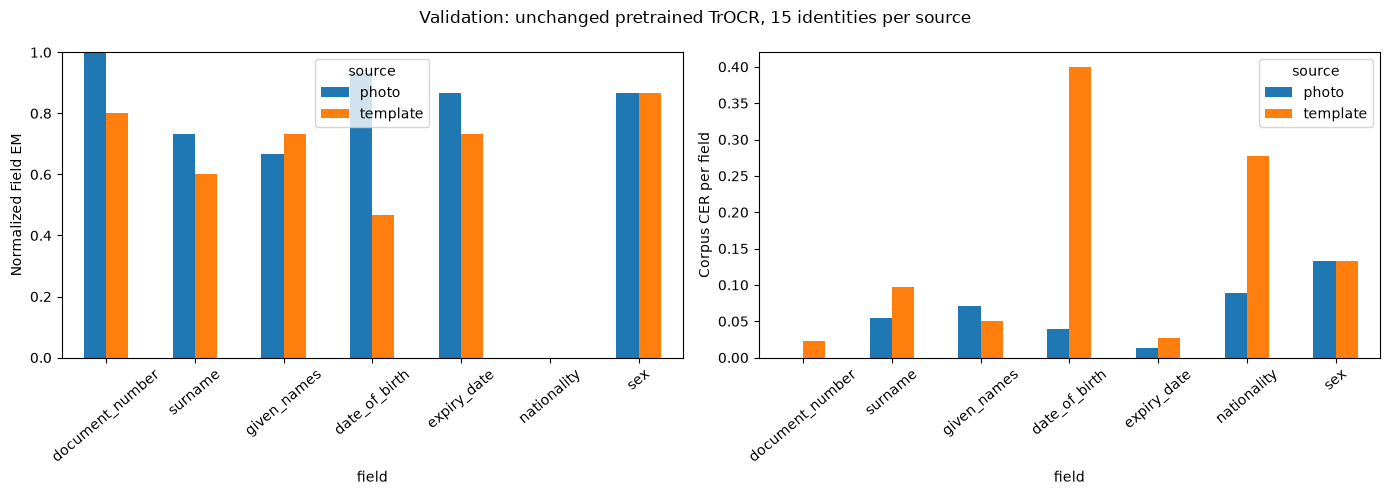

In [35]:
def write_jsonl(path, records):
    with path.open("w", encoding="utf-8") as stream:
        for record in records:
            stream.write(json.dumps(record, ensure_ascii=False, allow_nan=False) + "\n")

write_jsonl(artifact_directory / "field_predictions.jsonl", validation_field_rows)
write_jsonl(artifact_directory / "document_predictions.jsonl", validation_document_rows)
validation_fields.to_csv(artifact_directory / "field_predictions.csv", index=False)
per_field_accuracy.to_csv(artifact_directory / "per_field_accuracy.csv", index=False)
accuracy_summary.to_csv(artifact_directory / "accuracy_summary.csv", index=False)

# Recalculate from the serialized evidence, catching serialization or aggregation drift.
reloaded_fields = pd.read_json(artifact_directory / "field_predictions.jsonl", lines=True, dtype=False)
reloaded_documents = pd.read_json(artifact_directory / "document_predictions.jsonl", lines=True, dtype=False)
reloaded_per_field, reloaded_summary = summarize_scores(
    reloaded_fields, reloaded_documents, required_fields=required_field_names)
pd.testing.assert_frame_equal(accuracy_summary, reloaded_summary)
pd.testing.assert_frame_equal(per_field_accuracy, reloaded_per_field)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
per_field_accuracy.pivot(index="field", columns="source", values="field_em").reindex(required_field_names).plot.bar(ax=axes[0], ylim=(0, 1), rot=40)
axes[0].set_ylabel("Normalized Field EM")
per_field_accuracy.pivot(index="field", columns="source", values="cer").reindex(required_field_names).plot.bar(ax=axes[1], rot=40)
axes[1].set_ylabel("Corpus CER per field")
fig.suptitle("Validation: unchanged pretrained TrOCR, 15 identities per source")
fig.tight_layout()
fig.savefig(artifact_directory / "accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

## Workshop 7 — Time the seven-field request

### 7.1 Define the timer boundary

**Inference time** sums seven `model.generate` operations, including visual encoder
and autoregressive decoder. Crop creation, processor conversion, host/device
transfer, token decoding, normalization, and validation contribute to **end-to-end
time**. A request begins with the already canonical RGB card and ends with a
structured validated prediction. This matches the common input boundary for the
later OCR/Donut comparison. Raw-photo localization, rectification, disk reads,
model loading, scoring against truth, and file writes are outside the timer.

CUDA queues work asynchronously. Synchronize before starting and after each
generation call so the CPU wall clock measures completed GPU work. Nested timers
add synchronization overhead; this is recorded rather than claiming an optimized
serving latency. Float32, batch size one, and seven sequential field calls stay
fixed. The checkpoint has caching disabled, which is part of this baseline.

Three full warm-up requests per source are discarded. Then all 30 observations
are measured three times in seeded shuffled order: **45 requests per source**.
Repeated requests improve timing evidence, not correctness sample size. Median
describes the typical warm request; mean is sensitive to slow requests. No serving
tail-latency or concurrency conclusions are made from this small single-process run.

In [36]:
def timed_canonical_request(observation):
    torch.cuda.synchronize(inference_device)
    request_start = time.perf_counter()
    crops = extract_field_crops(observation, raw_to_canonical_field, field_crop_config)
    predictions, field_timings = {}, []
    for field_name, crop in crops.items():
        pixels = ocr_processor(images=crop["crop_rgb"], return_tensors="pt").pixel_values.to(inference_device)
        torch.cuda.synchronize(inference_device)
        inference_start = time.perf_counter()
        with torch.inference_mode():
            generated = ocr_model.generate(pixel_values=pixels, generation_config=ocr_generation_config)
        torch.cuda.synchronize(inference_device)
        inference_ms = (time.perf_counter() - inference_start) * 1000
        token_ids = generated[0].detach().cpu().tolist()
        predictions[field_name] = ocr_processor.decode(
            token_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)
        field_timings.append({"field": field_name, "inference_ms": inference_ms,
                              "generated_token_count": len(token_ids) - 1})
    normalized = normalize_document_values(predictions, required_field_names)
    validation = validate_document_values(
        normalized, required_fields=required_field_names, validation_config=alb_id_validation_config)
    torch.cuda.synchronize(inference_device)
    end_to_end_ms = (time.perf_counter() - request_start) * 1000
    return {"raw_predictions": predictions, "structured_fields": normalized, "validation": validation,
            "inference_ms": sum(row["inference_ms"] for row in field_timings),
            "end_to_end_ms": end_to_end_ms, "field_timings": field_timings}

baseline_by_observation = {(r["identity_key"], r["source"]): r for r in validation_document_rows}
torch.cuda.reset_peak_memory_stats(inference_device)
for source in ("template", "photo"):
    for key in validation_identity_keys[:latency_protocol["warmup_documents_per_source"]]:
        warmup = timed_canonical_request(observations[(key, source)])
        assert warmup["raw_predictions"] == baseline_by_observation[(key, source)]["raw_predictions"]
print("Six full-document warm-up requests completed and discarded.")

latency_rows, field_latency_rows = [], []
latency_rng = np.random.default_rng(2026)
observation_keys = list(observations)
for repetition in range(latency_protocol["measured_repetitions_per_observation"]):
    order = latency_rng.permutation(len(observation_keys))
    for position, index in enumerate(order):
        key, source = observation_keys[int(index)]
        timed = timed_canonical_request(observations[(key, source)])
        assert timed["raw_predictions"] == baseline_by_observation[(key, source)]["raw_predictions"], "Timing implementation changed recognition."
        assert timed["end_to_end_ms"] >= timed["inference_ms"] > 0
        common = {"run_id": run_id, "identity_key": key, "source": source,
                  "repetition": repetition, "order_position": position}
        latency_rows.append({**common, "inference_ms": timed["inference_ms"],
                             "end_to_end_ms": timed["end_to_end_ms"]})
        field_latency_rows.extend({**common, **row} for row in timed["field_timings"])
    print(f"Measured repetition {repetition + 1}/3 complete")
latency_measurements = pd.DataFrame(latency_rows)
field_latency_measurements = pd.DataFrame(field_latency_rows)
assert len(latency_measurements) == 90 and len(field_latency_measurements) == 630
assert latency_measurements.groupby(["identity_key", "source"]).size().eq(3).all()
latency_summary = latency_measurements.groupby("source", as_index=False).agg(
    requests=("inference_ms", "size"), inference_mean_ms=("inference_ms", "mean"),
    inference_median_ms=("inference_ms", "median"), inference_std_ms=("inference_ms", "std"),
    end_to_end_mean_ms=("end_to_end_ms", "mean"), end_to_end_median_ms=("end_to_end_ms", "median"),
    end_to_end_std_ms=("end_to_end_ms", "std"),
    end_to_end_min_ms=("end_to_end_ms", "min"), end_to_end_max_ms=("end_to_end_ms", "max"),
)
field_latency_summary = field_latency_measurements.groupby(["source", "field"], as_index=False).agg(
    calls=("inference_ms", "size"), mean_ms=("inference_ms", "mean"), median_ms=("inference_ms", "median"),
    mean_generated_tokens=("generated_token_count", "mean"))
run_metadata["runtime_observations"] = {
    "peak_torch_allocated_gib": torch.cuda.max_memory_allocated(inference_device) / 1024**3,
    "peak_torch_reserved_gib": torch.cuda.max_memory_reserved(inference_device) / 1024**3,
    "gpu_processes_after": command_output(["nvidia-smi", "--query-compute-apps=pid,process_name,used_memory", "--format=csv,noheader"]),
    "prediction_repetition_checks": "all six warmups and all 90 measured predictions identical to accuracy baseline",
}
save_json(artifact_directory / "run_metadata.json", run_metadata)
latency_measurements.to_csv(artifact_directory / "latency_measurements.csv", index=False)
field_latency_measurements.to_csv(artifact_directory / "field_latency_measurements.csv", index=False)
latency_summary.to_csv(artifact_directory / "latency_summary.csv", index=False)
field_latency_summary.to_csv(artifact_directory / "field_latency_summary.csv", index=False)
display(latency_summary)
display(field_latency_summary)

Six full-document warm-up requests completed and discarded.


Measured repetition 1/3 complete


Measured repetition 2/3 complete


Measured repetition 3/3 complete


,source,requests,inference_mean_ms,inference_median_ms,inference_std_ms,end_to_end_mean_ms,end_to_end_median_ms,end_to_end_std_ms,end_to_end_min_ms,end_to_end_max_ms
0,photo,45,269.139345,269.582473,4.115618,278.227766,277.398428,11.001957,267.002405,346.527207
1,template,45,260.803069,260.552482,4.065792,268.605334,268.393131,4.096373,261.076767,277.408028


,source,field,calls,mean_ms,median_ms,mean_generated_tokens
0,photo,date_of_birth,45,38.168275,37.905560,5.066667
1,photo,document_number,45,38.657241,38.179932,5.133333
2,photo,expiry_date,45,37.528630,37.898805,4.733333
3,photo,given_names,45,35.735358,35.367505,4.200000
4,photo,nationality,45,54.436335,54.352211,10.000000
5,photo,sex,45,29.256060,29.307248,2.000000
6,photo,surname,45,35.357446,35.157680,4.133333
7,template,date_of_birth,45,38.067056,37.807883,5.066667
8,template,document_number,45,38.142415,38.001199,5.066667
9,template,expiry_date,45,36.561092,37.493736,4.533333


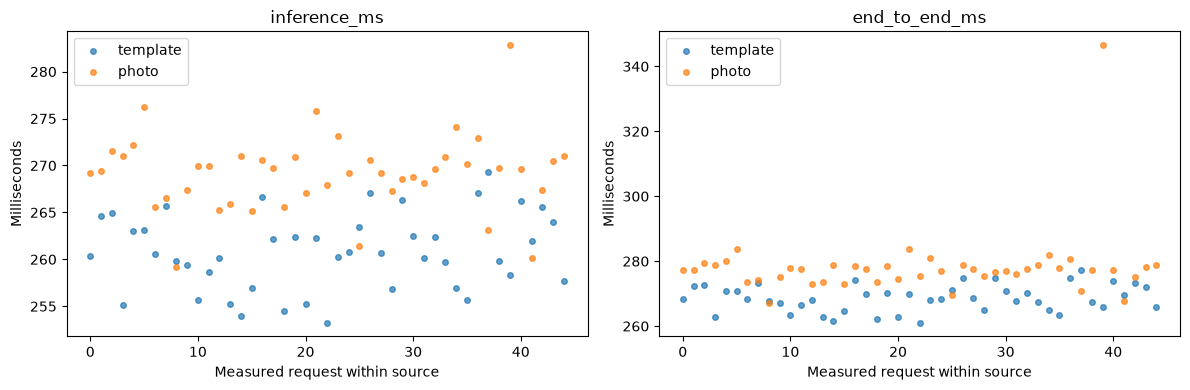

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["inference_ms", "end_to_end_ms"]):
    for source in ("template", "photo"):
        values = latency_measurements.loc[latency_measurements.source == source, metric].to_numpy()
        ax.scatter(np.arange(len(values)), values, s=16, alpha=0.7, label=source)
    ax.set(xlabel="Measured request within source", ylabel="Milliseconds", title=metric)
    ax.legend()
fig.tight_layout()
fig.savefig(artifact_directory / "latency.png", dpi=150, bbox_inches="tight")
plt.show()

**Workshop 7 reflection.** Why does timing only a GPU function call without
synchronization risk an underestimate? Why is a seven-field request slower than
one crop? Why would changing the cache, precision, decoding, or CPU thread policy
require a separate accuracy/latency experiment?

## Workshop 8 — Inspect errors and formulate the decision

### 8.1 Separate observed edit types from explanations

Edit distance establishes what differs in the output. It cannot establish why:
the same substitution could arise from a clipped crop, glare, a font mismatch,
or a decoder preference. The first table below is an automatic **symptom** summary.
The galleries are for assessing likely causes, with uncertainty retained.

Case/formatting differences resolved by normalization are counted separately from
remaining recognition errors. The seven-field baseline is never silently repaired
using ground truth, a nationality lookup, a new separator rule, or easier identities.

In [38]:
failures = validation_fields.loc[~validation_fields["normalized_exact_match"]].copy()
format_only = validation_fields.loc[
    ~validation_fields["raw_exact_match"] & validation_fields["normalized_exact_match"]].copy()

def edit_symptom(row):
    if row.normalized_prediction == "":
        return "empty prediction"
    if row.field == "sex":
        return "single-character failure"
    edits = [name for name in ["substitutions", "deletions", "insertions"] if getattr(row, name) > 0]
    return " + ".join(edits)

failures["edit_symptom"] = [edit_symptom(row) for row in failures.itertuples()]
failure_counts = failures.groupby(["source", "field", "edit_symptom"], as_index=False).size()
validation_vs_correctness = validation_fields.groupby(
    ["source", "prediction_is_valid", "normalized_exact_match"], as_index=False).size()
format_only_counts = format_only.groupby(["source", "field"], as_index=False).size()
display(failure_counts)
display(format_only_counts)
display(validation_vs_correctness)
display(failures[["identity_key", "source", "field", "raw_ground_truth", "raw_prediction", "normalized_prediction", "edit_distance", "validation_errors"]])
failures.to_csv(artifact_directory / "failures.csv", index=False)
failure_counts.to_csv(artifact_directory / "failure_counts.csv", index=False)
validation_vs_correctness.to_csv(artifact_directory / "validation_vs_correctness.csv", index=False)

,source,field,edit_symptom,size
0,photo,date_of_birth,substitutions + deletions + insertions,1
1,photo,expiry_date,substitutions,2
2,photo,given_names,substitutions,4
3,photo,given_names,substitutions + insertions,1
4,photo,nationality,substitutions,13
5,photo,nationality,substitutions + insertions,2
6,photo,sex,single-character failure,2
7,photo,surname,insertions,1
8,photo,surname,substitutions,3
9,template,date_of_birth,substitutions + deletions + insertions,8


,source,field,size
0,photo,given_names,10
1,photo,surname,11
2,template,given_names,11
3,template,surname,9


,source,prediction_is_valid,normalized_exact_match,size
0,photo,False,False,18
1,photo,True,False,11
2,photo,True,True,76
3,template,False,False,26
4,template,True,False,16
5,template,True,True,63


,identity_key,source,field,raw_ground_truth,raw_prediction,normalized_prediction,edit_distance,validation_errors
0,alb_id/00,template,document_number,367253746,357253746,357253746,1,[]
1,alb_id/00,template,surname,Agani,AGAINI,againi,1,[]
5,alb_id/00,template,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,snaptare/abangan,5,[unknown_nationality]
8,alb_id/00,photo,surname,Agani,AGAINI,againi,1,[]
9,alb_id/00,photo,given_names,Adnan,ADMAN,adman,1,[]
...,...,...,...,...,...,...,...,...
197,alb_id/98,template,surname,Ciftja,CIFIJA,cifija,1,[]
199,alb_id/98,template,date_of_birth,28-08-1965,28 08-1965,28 08-1965,9,[invalid_date]
201,alb_id/98,template,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,snaptare/abangan,5,[unknown_nationality]
204,alb_id/98,photo,surname,Ciftja,CITIJA,citija,2,[]


### 8.2 Review every failed crop

Each page shows actual recognizer inputs with reference and raw/normalized output.
The display enlarges the crop for inspection but never feeds that enlargement
back into inference. Pairing with the same identity's other source helps separate
capture effects from repeated recognition trouble. Processor inputs are checked
next so a readable original is not confused with a readable model input.

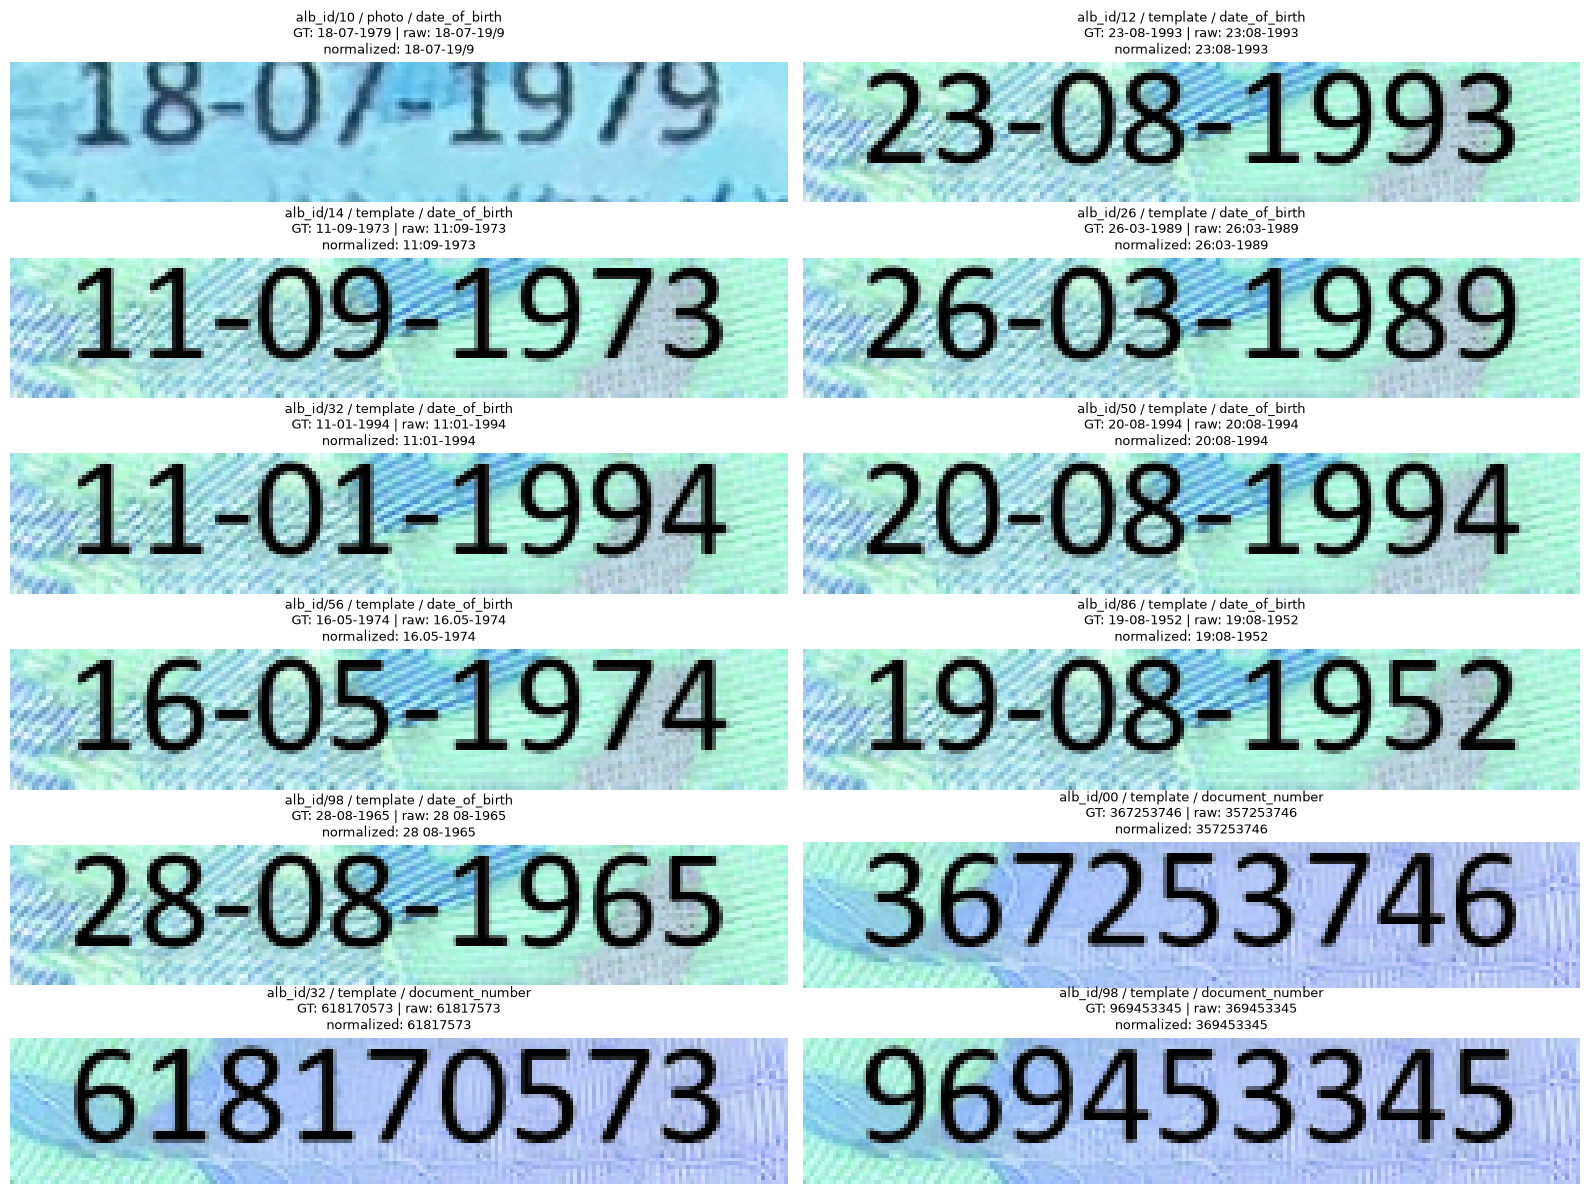

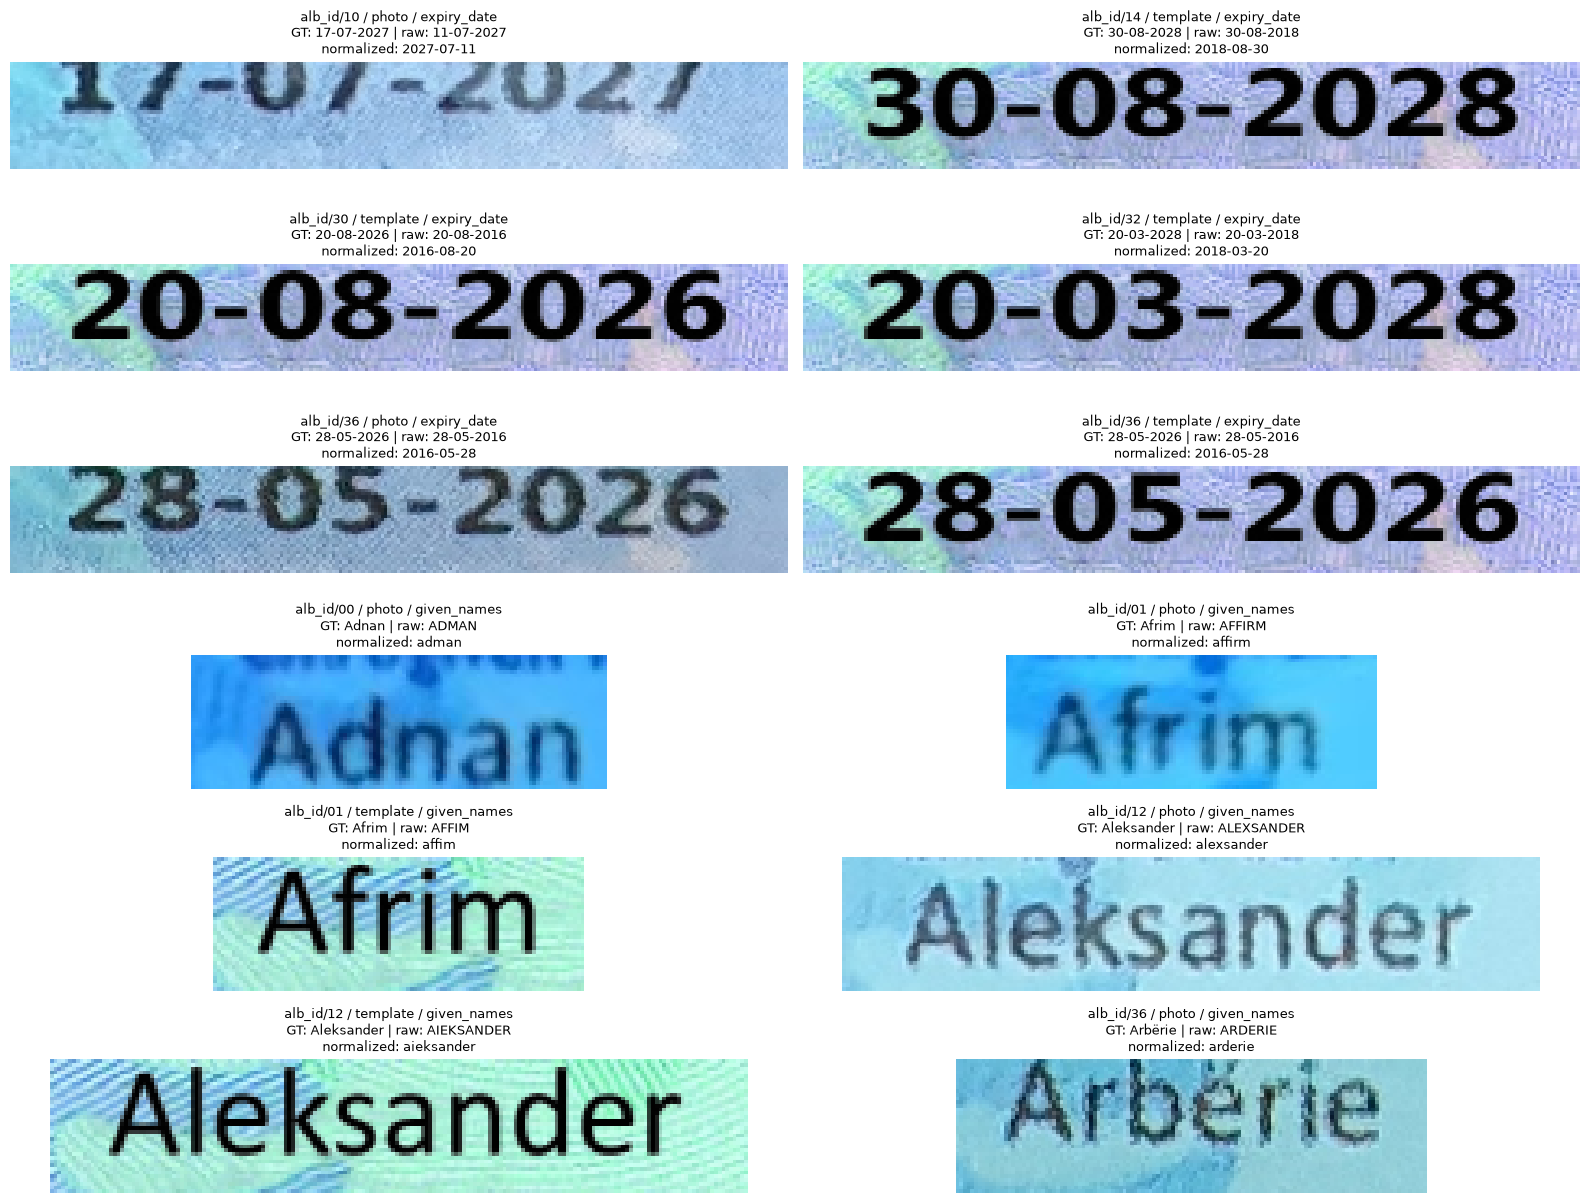

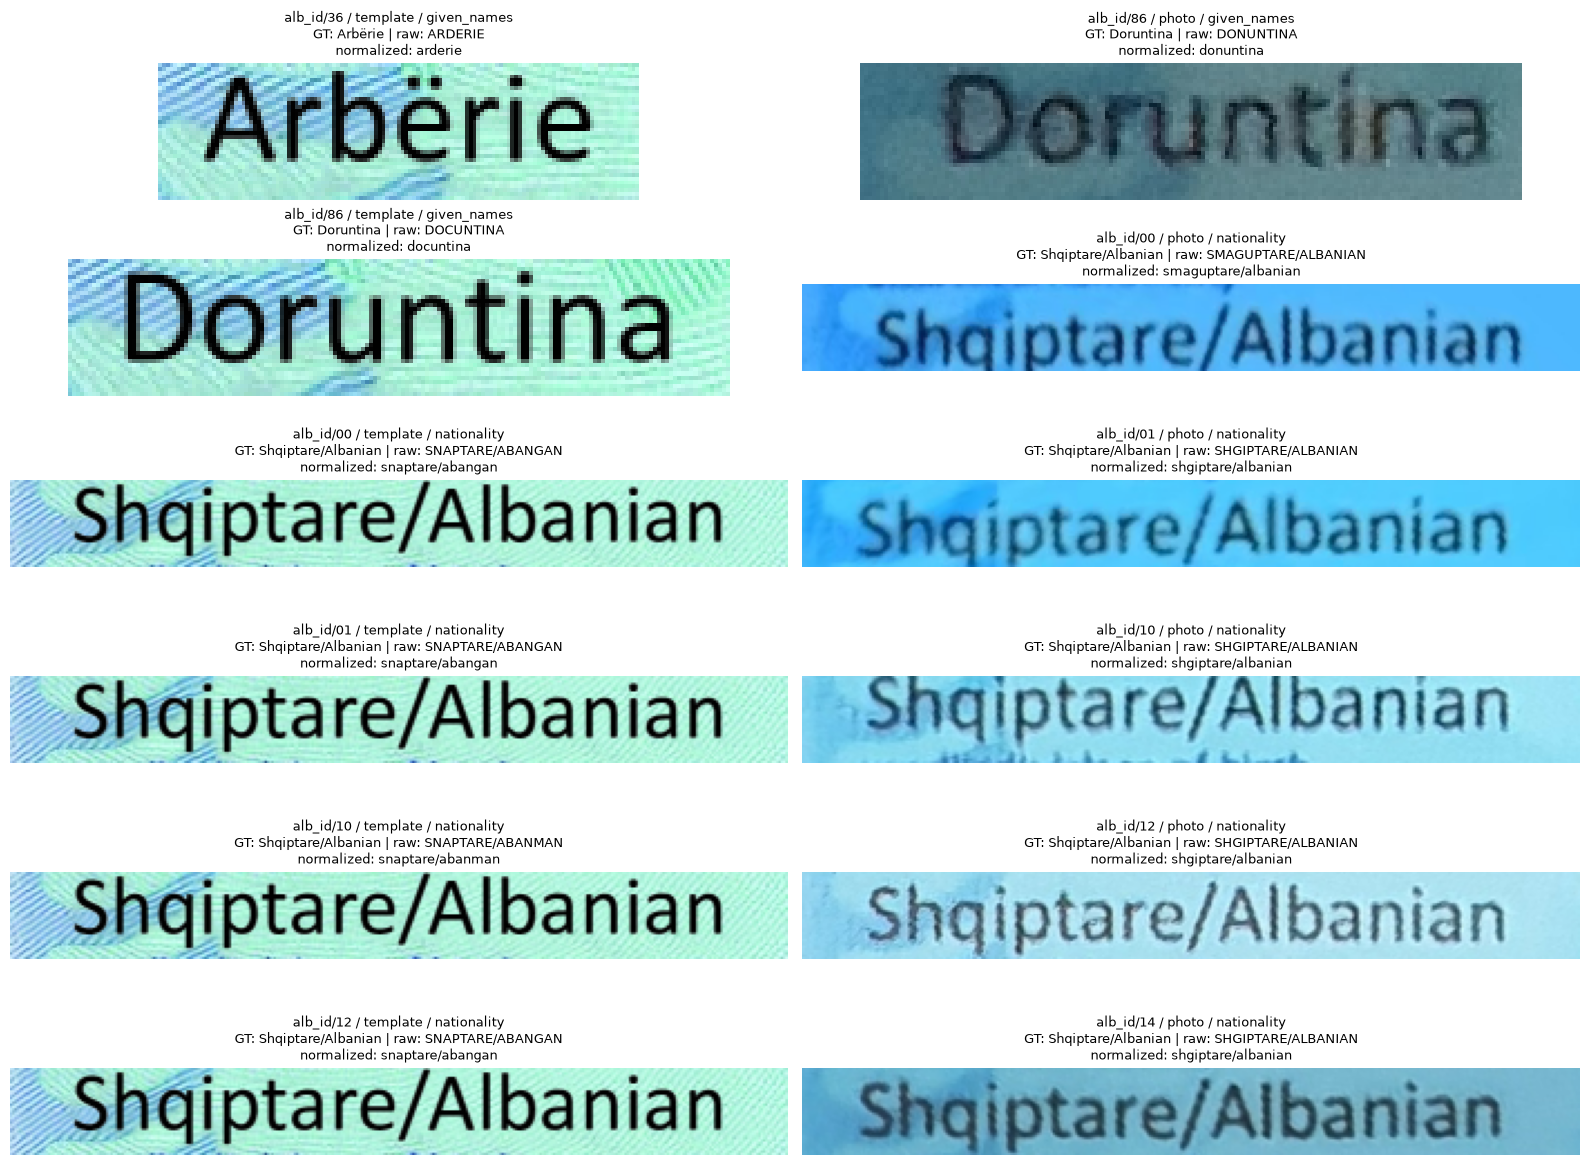

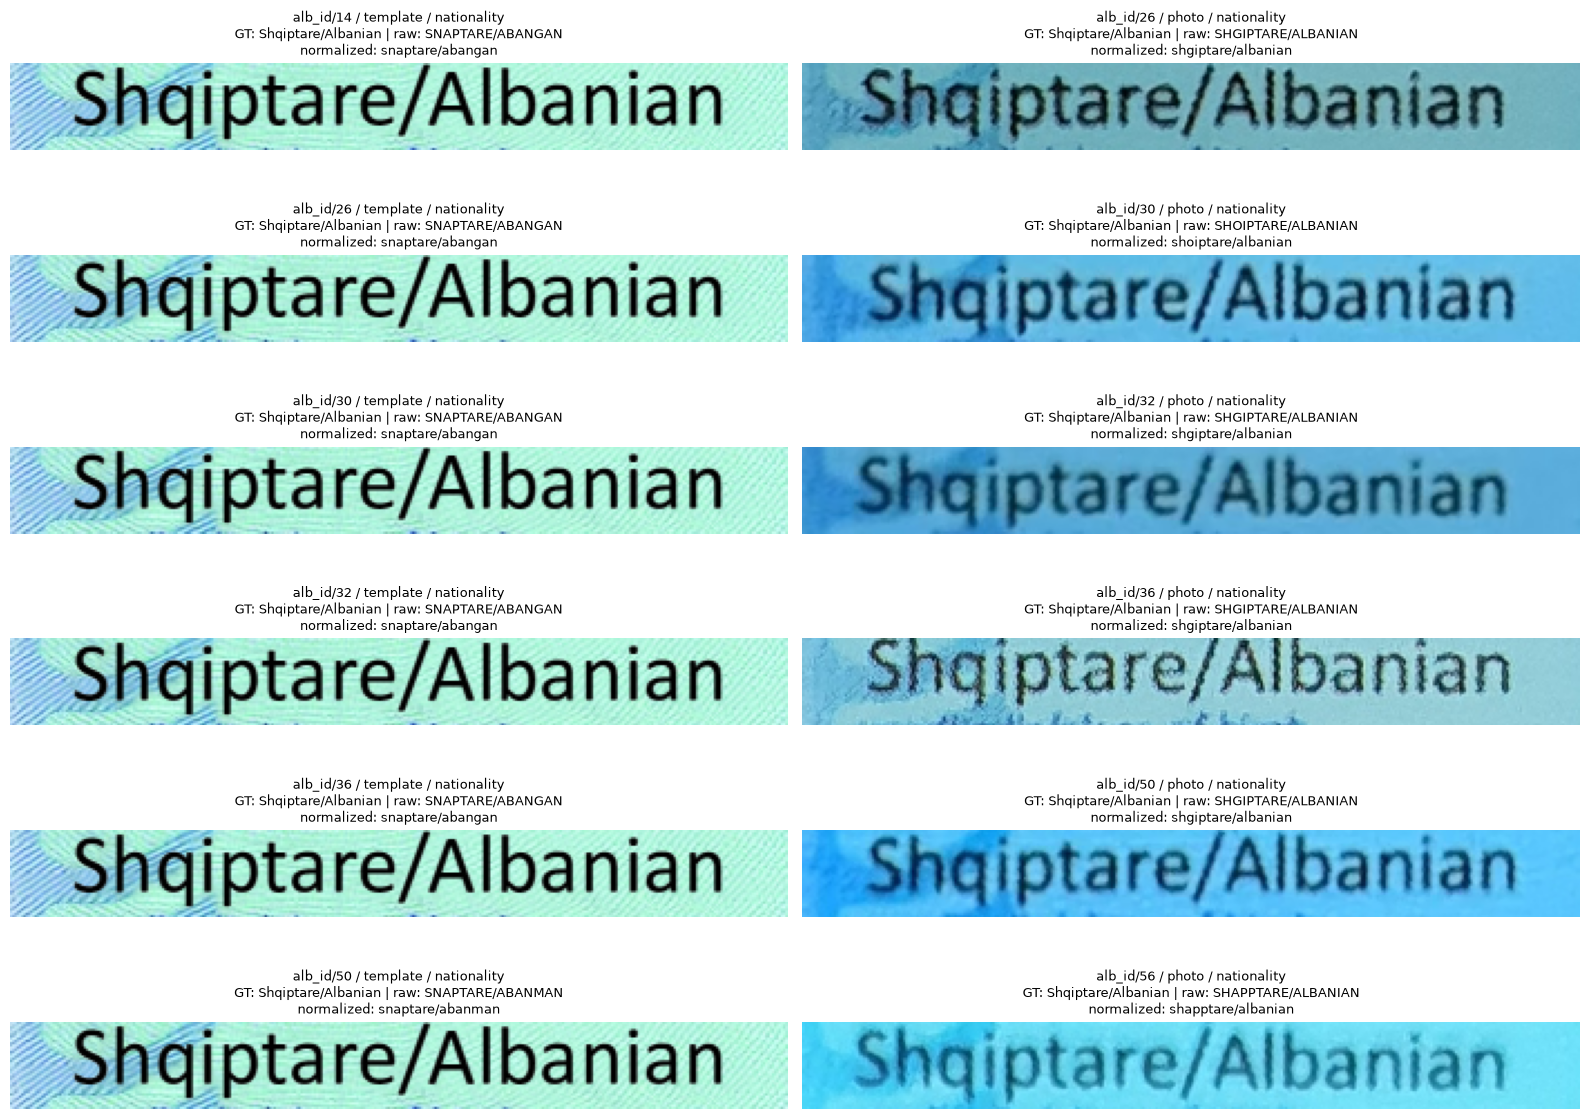

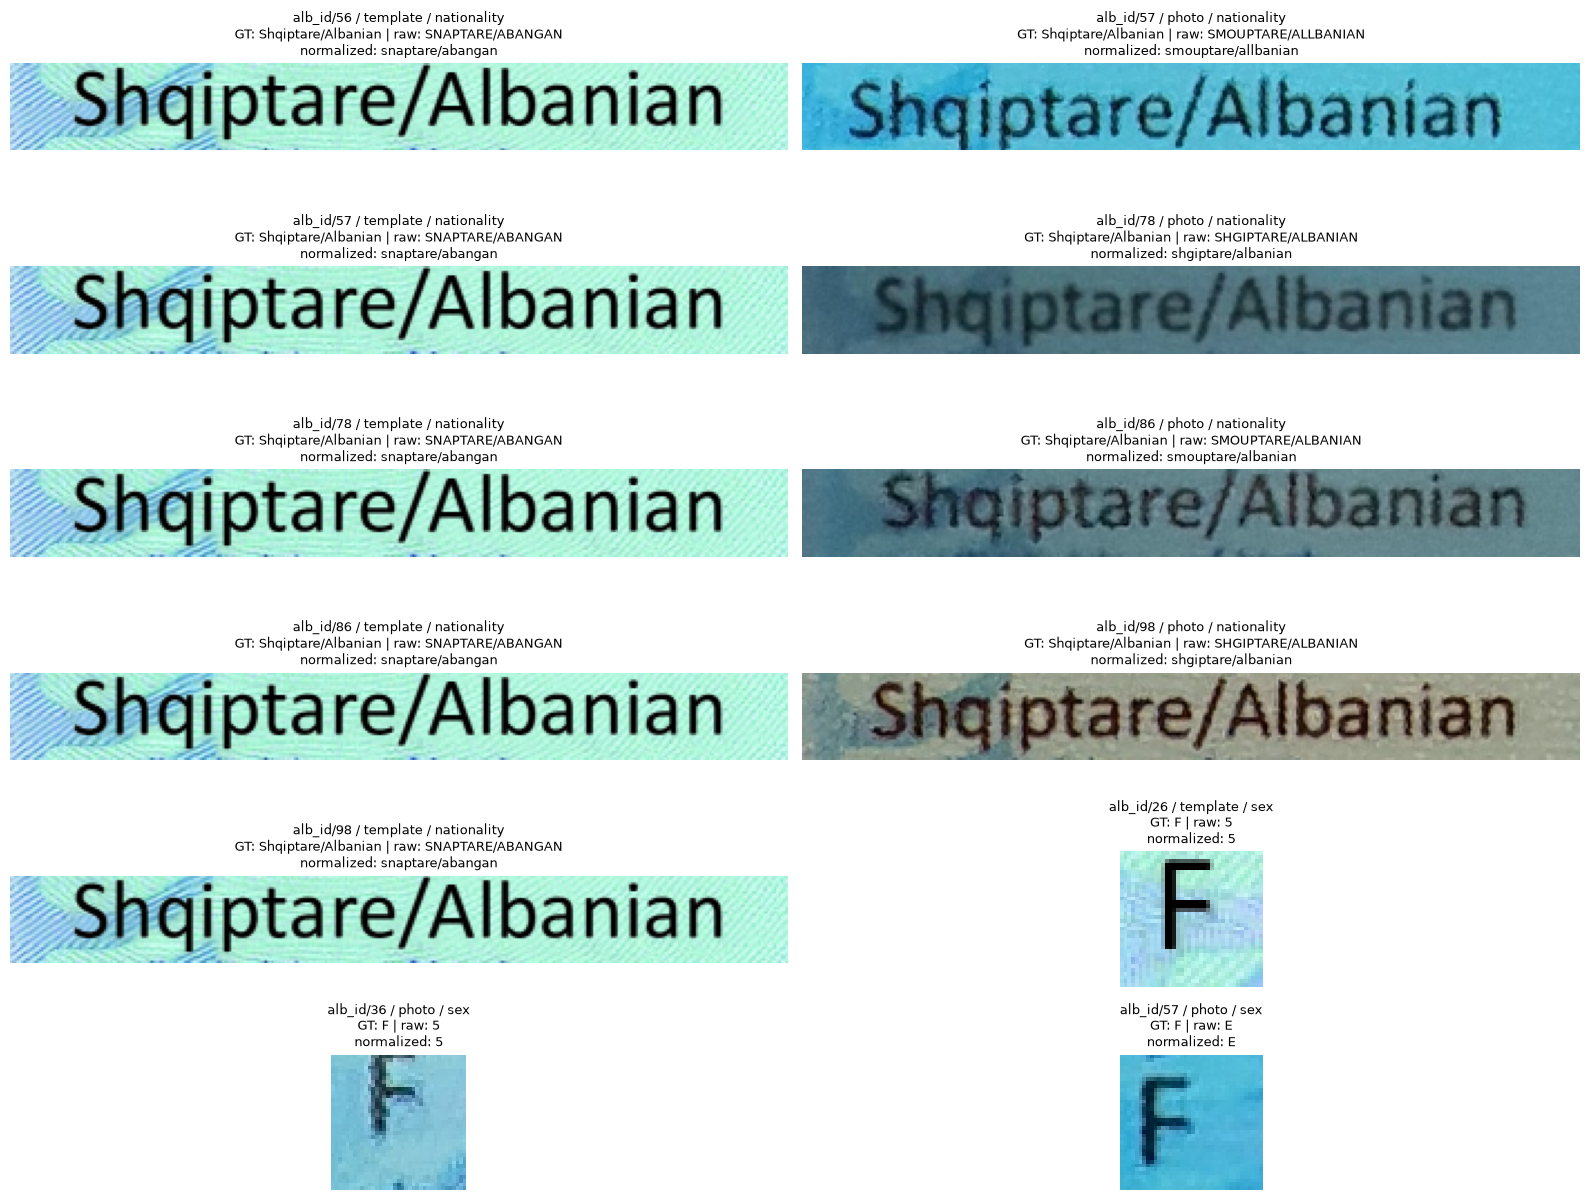

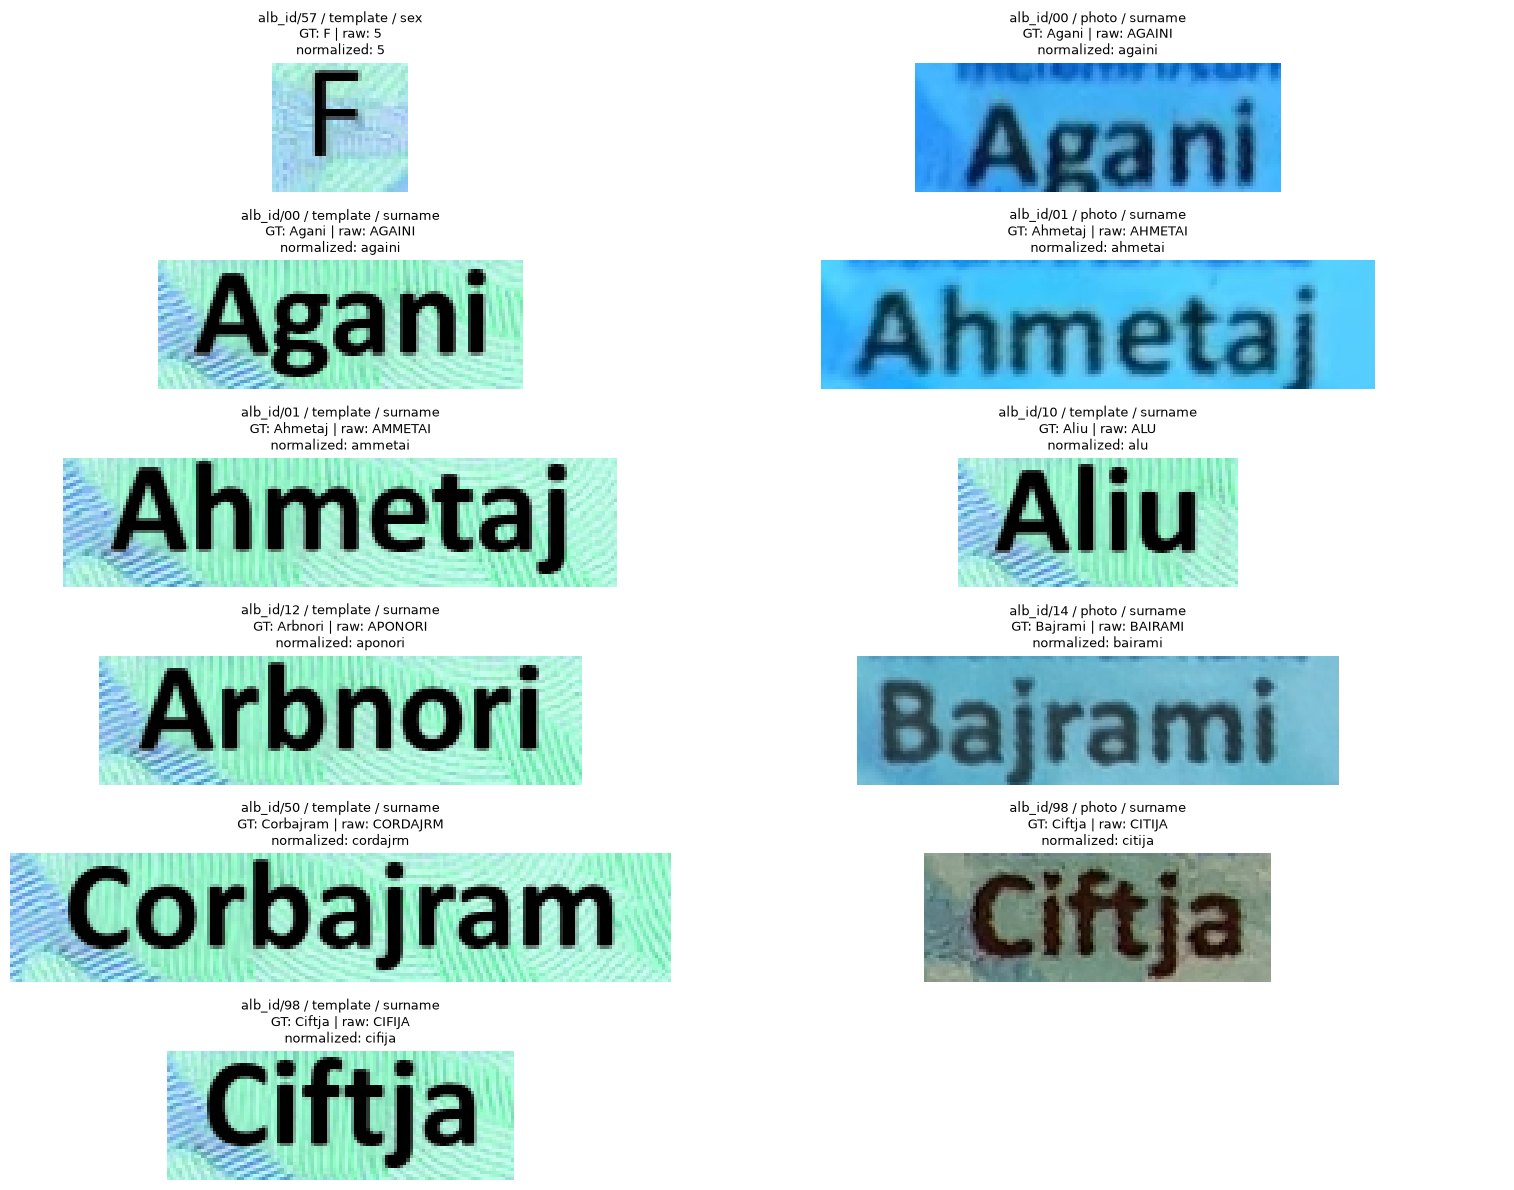

Failed fields: 71 across 6 gallery pages


In [39]:
crop_cache = {key: extract_field_crops(obs, raw_to_canonical_field, field_crop_config)
              for key, obs in observations.items()}
gallery_paths = []
ordered_failures = failures.sort_values(["field", "identity_key", "source"])
for page_start in range(0, len(ordered_failures), 12):
    page = ordered_failures.iloc[page_start:page_start + 12]
    fig, axes = plt.subplots(6, 2, figsize=(16, 12))
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, page.itertuples()):
        crop = crop_cache[(row.identity_key, row.source)][row.field]["crop_rgb"]
        ax.imshow(crop)
        ax.set_title(f"{row.identity_key} / {row.source} / {row.field}\nGT: {row.raw_ground_truth} | raw: {row.raw_prediction}\nnormalized: {row.normalized_prediction}", fontsize=9)
    fig.tight_layout()
    path = artifact_directory / f"failure_gallery_{page_start // 12 + 1:02d}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    gallery_paths.append(path)
    plt.show()
print("Failed fields:", len(failures), "across", len(gallery_paths), "gallery pages")

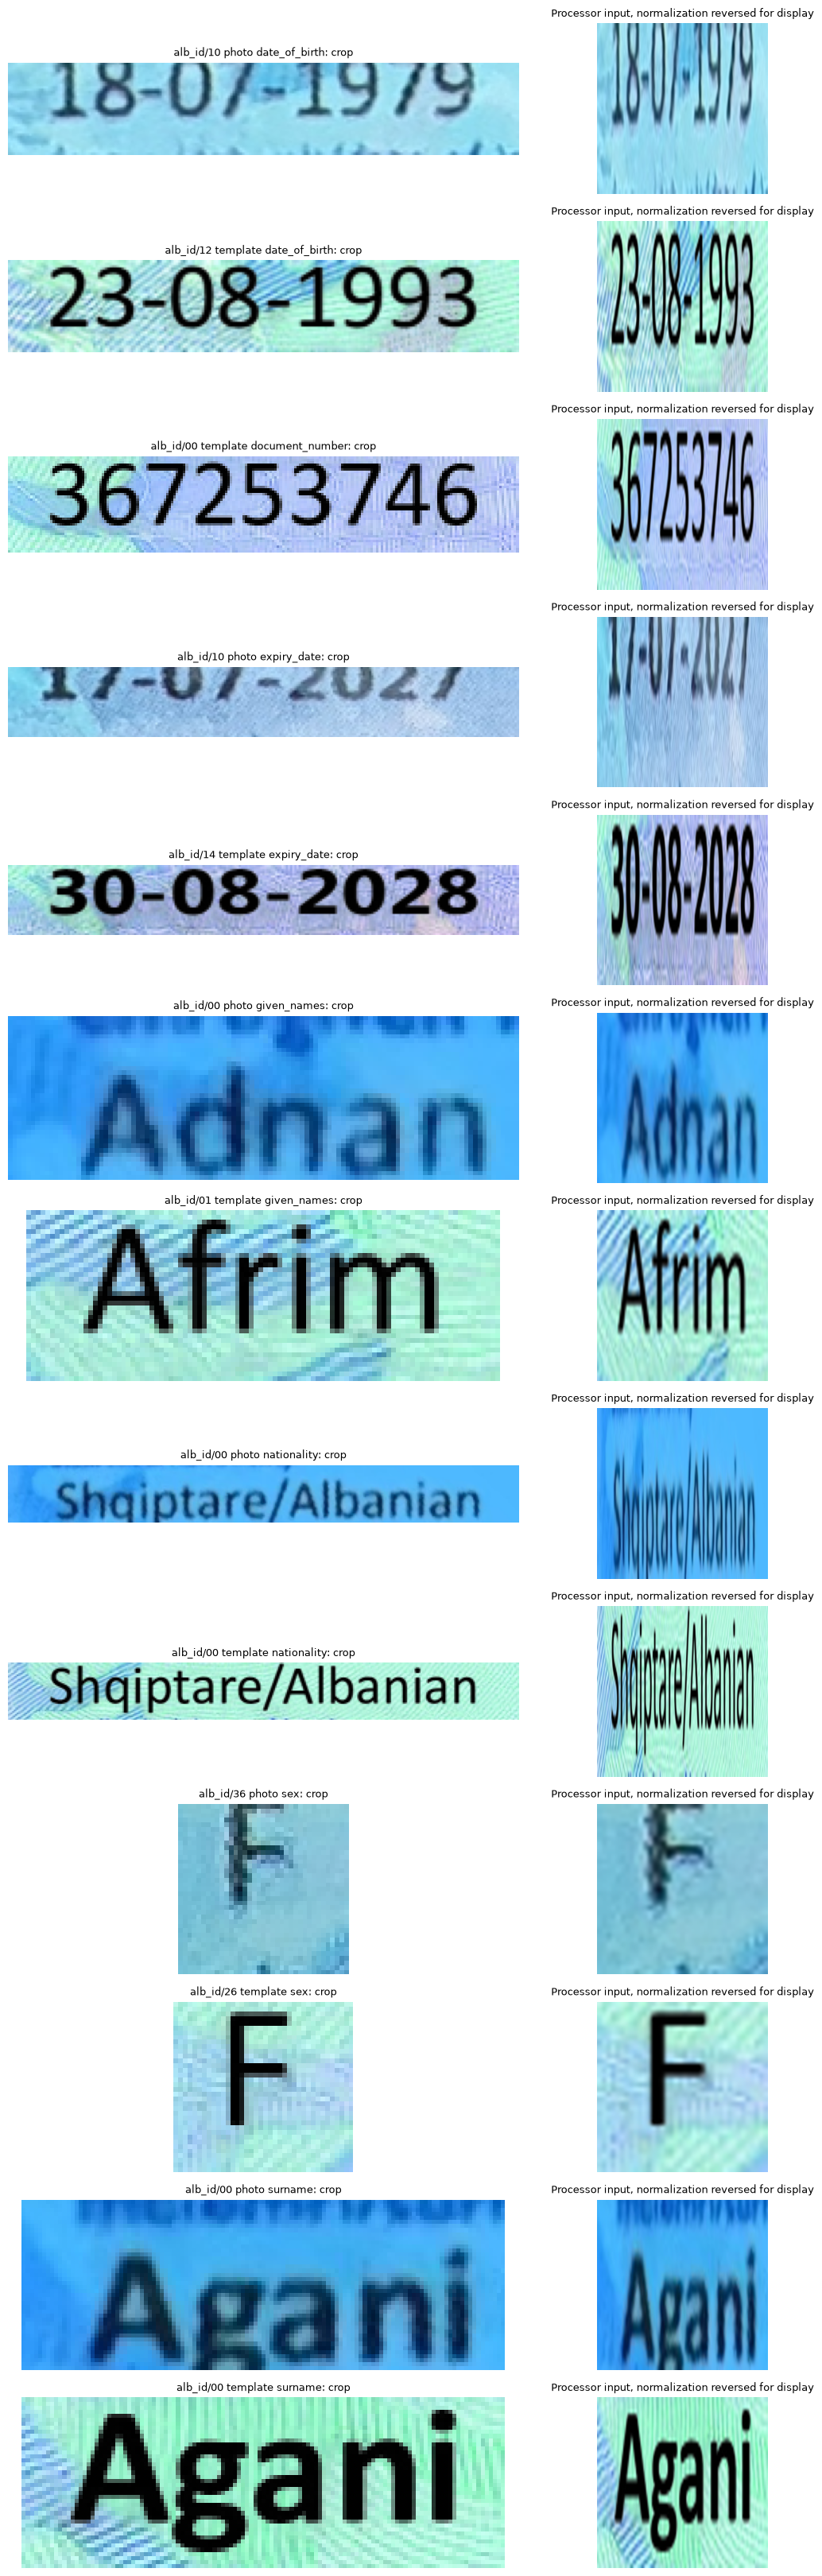

In [40]:
# One example per failing field/source, chosen deterministically, to audit model preprocessing.
representatives = failures.sort_values(["field", "source", "identity_key"]).groupby(["field", "source"], as_index=False).head(1)
processor_audit_rows = []
fig, axes = plt.subplots(len(representatives), 2, figsize=(12, max(3, 2.5 * len(representatives))), squeeze=False)
for axes_row, row in zip(axes, representatives.itertuples()):
    crop = crop_cache[(row.identity_key, row.source)][row.field]["crop_rgb"]
    pixels = ocr_processor(images=crop, return_tensors="pt").pixel_values
    assert pixels.shape == (1, 3, 384, 384) and pixels.dtype == torch.float32
    assert torch.isfinite(pixels).all()
    mean = np.asarray(ocr_processor.image_processor.image_mean)
    std = np.asarray(ocr_processor.image_processor.image_std)
    reconstructed = np.clip(pixels[0].permute(1, 2, 0).numpy() * std + mean, 0, 1)
    axes_row[0].imshow(crop)
    axes_row[1].imshow(reconstructed)
    axes_row[0].set_title(f"{row.identity_key} {row.source} {row.field}: crop", fontsize=9)
    axes_row[1].set_title("Processor input, normalization reversed for display", fontsize=9)
    for ax in axes_row:
        ax.axis("off")
    processor_audit_rows.append({"identity_key": row.identity_key, "source": row.source, "field": row.field,
        "crop_width": crop.shape[1], "crop_height": crop.shape[0], "tensor_min": pixels.min().item(),
        "tensor_max": pixels.max().item(), "input_shape": list(pixels.shape)})
fig.tight_layout()
fig.savefig(artifact_directory / "processor_audit.png", dpi=110, bbox_inches="tight")
plt.show()
pd.DataFrame(processor_audit_rows).to_csv(artifact_directory / "processor_audit.csv", index=False)

### 8.3 A training-only input-resize control

Readable crops alone cannot exclude a model-preprocessing sensitivity. The
processor stretches each line to a square. As a diagnostic, compare that fixed
baseline with centering the unmodified crop on a white square before applying
the same processor. This preserves character aspect ratio but also adds a large
blank region. It tests one alternative, not all possible preprocessing policies.

Select the first three training identities plus the first training identity with
`F`, then inspect nationality, birth date, given names, and sex on both sources.
Selection uses the manifest and training labels, never validation errors. No
validation result above is replaced, and this control does not change the crop
geometry, model, normalization, or reported baseline configuration.

If the alternative helps, it warrants a separate controlled experiment. If it
does not, that weakens this particular simple fix without proving preprocessing
can never help. A single constant nationality string also limits how much one
can infer about general recognition from this field.

In [41]:
training_keys = sorted(split_manifest.loc[split_manifest.split == "train", "identity_key"])
female_training_key = next(
    key for key in training_keys
    if find_field_region(template_records_by_filename[f"{manifest_by_identity.loc[key, 'sample_id']}.jpg"], "gender")["region_attributes"]["value"] == "F")
control_identity_keys = list(dict.fromkeys(training_keys[:3] + [female_training_key]))
assert all(manifest_by_identity.loc[key, "split"] == "train" for key in control_identity_keys)

def white_square_crop(crop):
    height, width = crop.shape[:2]
    side = max(height, width)
    canvas = np.full((side, side, 3), 255, dtype=np.uint8)
    x, y = (side - width) // 2, (side - height) // 2
    canvas[y:y + height, x:x + width] = crop
    return canvas

control_rows = []
control_fields = ("nationality", "date_of_birth", "given_names", "sex")
for key in control_identity_keys:
    assets = load_alb_id_assets(
        key, manifest_index=manifest_by_identity, dataset_root=dataset_root,
        template_record_index=template_records_by_filename, photo_record_index=photo_records_by_filename)
    for source in ("template", "photo"):
        observation = make_canonical_observation(assets, source, canonical_width, canonical_height)
        crops = extract_field_crops(observation, raw_to_canonical_field, field_crop_config)
        for field in control_fields:
            crop = crops[field]
            for variant in ("baseline_stretch", "white_square"):
                pixels = crop["crop_rgb"] if variant == "baseline_stretch" else white_square_crop(crop["crop_rgb"])
                result = recognize_field_crop(
                    pixels, processor=ocr_processor, model=ocr_model, device=inference_device,
                    generation_config=ocr_generation_config)
                truth = normalize_field_value(field, crop["ground_truth"])
                prediction = normalize_field_value(field, result["raw_prediction"])
                control_rows.append({"identity_key": key, "split": "train", "source": source,
                    "field": field, "variant": variant, "raw_ground_truth": crop["ground_truth"],
                    "raw_prediction": result["raw_prediction"], "normalized_prediction": prediction,
                    "normalized_exact_match": prediction == truth})
preprocessing_control = pd.DataFrame(control_rows)
control_summary = preprocessing_control.groupby(["source", "field", "variant"], as_index=False).agg(
    samples=("field", "size"), matches=("normalized_exact_match", "sum"))
control_summary["field_em"] = control_summary.matches / control_summary.samples
assert set(preprocessing_control.split) == {"train"}
assert not set(control_identity_keys) & set(validation_identity_keys)
assert len(preprocessing_control) == len(control_identity_keys) * 2 * 4 * 2
preprocessing_control.to_csv(artifact_directory / "training_preprocessing_control.csv", index=False)
control_summary.to_csv(artifact_directory / "training_preprocessing_control_summary.csv", index=False)
run_metadata["training_preprocessing_control"] = {
    "identity_keys": control_identity_keys, "fields": list(control_fields),
    "variants": ["baseline_stretch", "white_square"],
    "role": "training-only diagnosis; not part of validation score or latency", "changes_to_baseline": False}
save_json(artifact_directory / "run_metadata.json", run_metadata)
display(control_summary)
display(preprocessing_control.loc[preprocessing_control.field == "nationality"])

,source,field,variant,samples,matches,field_em
0,photo,date_of_birth,baseline_stretch,4,4,1.00
1,photo,date_of_birth,white_square,4,0,0.00
2,photo,given_names,baseline_stretch,4,1,0.25
3,photo,given_names,white_square,4,0,0.00
4,photo,nationality,baseline_stretch,4,0,0.00
5,photo,nationality,white_square,4,0,0.00
6,photo,sex,baseline_stretch,4,4,1.00
7,photo,sex,white_square,4,4,1.00
8,template,date_of_birth,baseline_stretch,4,2,0.50
9,template,date_of_birth,white_square,4,0,0.00


,identity_key,split,source,field,variant,raw_ground_truth,raw_prediction,normalized_prediction,normalized_exact_match
0,alb_id/02,train,template,nationality,baseline_stretch,Shqiptare/Albanian,SNAPTARE/ABANGAN,snaptare/abangan,False
1,alb_id/02,train,template,nationality,white_square,Shqiptare/Albanian,---,---,False
8,alb_id/02,train,photo,nationality,baseline_stretch,Shqiptare/Albanian,SHGIPTARE/ALBANIAN,shgiptare/albanian,False
9,alb_id/02,train,photo,nationality,white_square,Shqiptare/Albanian,--,--,False
16,alb_id/03,train,template,nationality,baseline_stretch,Shqiptare/Albanian,SNAPTARE/ABANGAN,snaptare/abangan,False
17,alb_id/03,train,template,nationality,white_square,Shqiptare/Albanian,---,---,False
24,alb_id/03,train,photo,nationality,baseline_stretch,Shqiptare/Albanian,SHGIPTARE/ATBANIAN,shgiptare/atbanian,False
25,alb_id/03,train,photo,nationality,white_square,Shqiptare/Albanian,---------,---------,False
32,alb_id/04,train,template,nationality,baseline_stretch,Shqiptare/Albanian,SNAPTARE/ABANGAN,snaptare/abangan,False
33,alb_id/04,train,template,nationality,white_square,Shqiptare/Albanian,---,---,False


### 8.4 Compare paired errors and retain a decision gate

A field failing on both clean and captured versions of the same identity suggests
a shared recognition/domain problem, but shared crop geometry is another possible
cause; the visual audit matters. A photo-only failure suggests a capture or
rectification effect. Different predictions across sources are expected when
their pixels differ.

The table below is evidence for deciding whether to attempt Workshop 9. It is
not an approval to train or a final pipeline freeze. Fine-tuning would need a
specific hypothesis, training-only crop/transcription pairs, a validation-based
selection rule, and a compute budget. The baseline and scoring contract must be
retained to assess whether the intervention helped.

In [42]:
paired = validation_fields.pivot(index=["identity_key", "field"], columns="source", values="normalized_exact_match")
paired["outcome"] = np.select(
    [paired.template & paired.photo, paired.template & ~paired.photo, ~paired.template & paired.photo],
    ["both correct", "photo only fails", "template only fails"], default="both fail")
paired_counts = paired.reset_index().groupby(["field", "outcome"], as_index=False).size()
display(paired_counts)
paired_counts.to_csv(artifact_directory / "paired_outcomes.csv", index=False)

observed_findings = {
    "run_id": run_id, "accuracy": accuracy_summary.to_dict(orient="records"),
    "per_field": per_field_accuracy.to_dict(orient="records"),
    "latency": latency_summary.to_dict(orient="records"),
    "failed_fields": len(failures), "format_only_fields": len(format_only),
    "length_limit_hits": int(validation_fields["length_limit_hit"].sum()),
    "workshop9_status": "pending user decision", "phase3_status": "open",
}
save_json(artifact_directory / "findings.json", observed_findings)
print("Measured artifacts:", artifact_directory)

,field,outcome,size
0,date_of_birth,both correct,6
1,date_of_birth,photo only fails,1
2,date_of_birth,template only fails,8
3,document_number,both correct,12
4,document_number,template only fails,3
5,expiry_date,both correct,10
6,expiry_date,both fail,1
7,expiry_date,photo only fails,1
8,expiry_date,template only fails,3
9,given_names,both correct,10


Measured artifacts: /home/raspiestchip/kyc-router/outputs/phase3/20261012T220250890693Z


### 8.5 Interpretation after visual review

The saved validation run has **71 failed fields**: 42 template and 29 photo
failures. All six failure-gallery pages and the processor audit were reviewed.
The following are diagnostic groups, not experimentally proven causal labels:

| Diagnostic group | Template | Photo | Evidence and limitation |
|---|---:|---:|---|
| Nationality recognition/domain mismatch | 15 | 15 | Full readable text remains in the crops; wrong on both sources for all identities. The template often produces the same wrong sequence. |
| Birth-date punctuation/character errors | 8 | 1 | Eight template predictions change the first hyphen to `:`, `.`, or a space. Photo `alb_id/10` reads a year digit as `/`; tight upper crop alignment may contribute. |
| Expiry-date digit errors | 4 | 2 | Five of six failures read a `202x` year as `201x`; one photo changes day 17 to 11. All six outputs still parse as dates. |
| Document-number digit errors | 3 | 0 | Two substitutions and one deletion on legible template crops; two wrong outputs still satisfy the nine-digit rule. |
| Given-name and surname errors | 10 | 9 | Substitutions, insertions, deletions, and the diacritic in `Arbërie`; several names fail in both sources. Blurred photos and nearby label fragments are possible cofactors. |
| Single-character sex errors | 2 | 2 | Every failure is a visible `F` transcribed as `5` or `E`; template examples are also affected. |

The 41 raw-only mismatches become correct through the existing representation
rules. Those are not remaining recognition failures. Another **27 wrong fields
pass semantic validation**, demonstrating why validators cannot substitute for
ground-truth correctness. No missing keys, structural failures, or generation
length-limit hits occurred.

**Templates do not outperform photographs in this run.** Photographs achieve
76/105 normalized field matches versus 63/105 for templates. The largest gaps
are birth dates and nationality character error. Capture/resampling changes the
pixels and the interaction with printed fonts/background patterns. We have not
isolated which factor explains the reversal, so it is not a general claim that
capture improves OCR.

The malformed template dates deserve special care: truth is normalized to
year-first order, but an unsupported predicted date stays day-first. Its CER
therefore includes both the punctuation error and the resulting representation
difference. The high date CER is contract-correct but is not a claim that all
those printed digits are unreadable. The raw text and images show the distinction.

The training-only white-square control achieved **8/32** matches versus the
unchanged processor's **18/32**. Nationality remained **0/8** for both variants,
and white padding often produced only hyphens. Adding large blank areas changes
the model input distribution; preserving aspect ratio alone did not solve the
problem. This rejects that particular simple alternative on these training
examples, not every possible preprocessing improvement. The baseline is retained.

**Recommendation for discussion:** the evidence supports attempting a small,
controlled Workshop 9 adaptation experiment. The hypothesis is that training on
readable identity-field crop/transcription pairs can reduce the repeated printed
font, character, separator, and short-field errors. It is supported by failures
on readable templates, repeated cross-source errors, and the negative simple
preprocessing control. Crop alignment and other preprocessing alternatives remain
possible contributors; the evidence does not prove training is the only remedy.

Any approved experiment should use the 70 training identities only, preserve
diacritics and exact labels, select checkpoints using normalized validation macro
Field EM, and compare every field against this untouched baseline. Because
nationality is constant in this dataset, improving that field alone could reflect
memorization; improvements on names, dates, and numbers are also needed to
support broader adaptation claims. CPU/GPU settings and timing must be recorded
again for a selected candidate. **No training or final freeze is authorized by
this recommendation; the user decides next.**

### Handoff: stop after Workshop 8

The run has measured the pretrained validation baseline, audited metrics and
serialized predictions, measured warm latency, and generated failure evidence.
The accompanying [Workshop 5–8 report](../docs/experiments/ocr-baseline.md) records
the visual findings and a concrete fine-tuning hypothesis after inspection.

**Phase 3 remains open.** No Workshop 9 training, final checkpoint freeze, source
extraction, Phase 4 implementation, synthetic degradation benchmark, or test-set
evaluation is performed here.

Review prompts: identify a plausible but wrong value that passes validation;
explain a raw-only mismatch and a real character error; name the timer boundary;
explain which failure evidence could justify fine-tuning and which cannot be
resolved by training alone. These remain learning checkpoints, not claims that
the learner has already mastered the material.